## Measuring Urban From

In [1]:
# Import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import geopandas as gpd



from urllib.request import urlopen
import json
from IPython.display import Image

import plotly.io as pio
import plotly.express as px       # 편리한 plot 설정 
import plotly.graph_objects as go # 디테일하게 plot을 설정
import plotly.figure_factory as ff
from plotly.subplots import make_subplots


### 행정동 경계 및 건물


```python

# 전국행정동 경계 불러오기
bnd_dong = gpd.read_file(
    "shp/bnd_all_00_2025_2Q/bnd_dong_00_2025_2Q.shp"
)


# 서울시만 추출
bnd_dong = bnd_dong[
    bnd_dong["ADM_CD"].astype(str).str.startswith("11")
]

# 서울시만 shp로 저장
bnd_dong.to_file(
    "shp/bnd_dong_seoul.shp",
    driver="ESRI Shapefile",
    encoding="UTF-8",
)
```

In [5]:
# 서울시 행정동 경계

bnd_dong = gpd.read_file(
    "shp/bnd_dong_seoul.shp"
)

print(bnd_dong.shape)
print(bnd_dong.crs)
bnd_dong

(426, 4)
EPSG:5179


,BASE_DATE,ADM_CD,ADM_NM,geometry
0,20250630,11010530,사직동,"POLYGON ((953553.932 1953335.741, 953555.211 1..."
1,20250630,11010540,삼청동,"POLYGON ((953844.082 1955492.177, 953858.644 1..."
2,20250630,11010550,부암동,"POLYGON ((952490.38 1956548.821, 952497.594 19..."
3,20250630,11010560,평창동,"POLYGON ((953683.828 1959209.871, 953665.283 1..."
4,20250630,11010570,무악동,"POLYGON ((952298.144 1953539.606, 952324.838 1..."
...,...,...,...,...
421,20250630,11250730,천호2동,"POLYGON ((966110.271 1950148.101, 966118.161 1..."
422,20250630,11250740,길동,"POLYGON ((968944.218 1949625.263, 968943.832 1..."
423,20250630,11250750,강일동,"POLYGON ((971452.641 1953347.663, 971446.624 1..."
424,20250630,11250760,상일1동,"POLYGON ((971190.564 1949669.365, 971193.744 1..."


# TL_SPBD_BULD_11_202609 코드북

## 데이터 개요

| 항목 | 내용 |
|---|---|
| 파일 | `TL_SPBD_BULD_11_202609.shp` |
| 주제 | 서울특별시 도로명주소 전자지도 건물 공간자료 |
| 레코드 수 | 591,303개 (DBF 기준) |
| 도형 | 건물 폴리곤 |
| 좌표계 | EPSG:5179 (Korea 2000 / Unified CS, 단위: 미터) |
| 속성 인코딩 | 한글이 깨지면 GeoPandas에서 `encoding="cp949"` 지정 |

이 파일은 도로명주소 건물 레이어(`TL_SPBD_BULD`)의 서울특별시 자료입니다. 아래 자료형과 필드 폭은 Shapefile DBF 헤더에서 읽은 값입니다. 설명은 도로명주소 전자지도 속성 명칭을 기준으로 정리했습니다. 코드 필드의 개별 코드값 뜻은 별도 코드표를 확인해야 합니다.

## 속성 필드

| 필드명 | 한글명 | DBF 형식 | 설명 |
|---|---|---:|---|
| `BDTYP_CD` | 건물용도코드 | 문자(5) | 건물 용도를 나타내는 코드 |
| `BD_MGT_SN` | 이전건물관리번호 | 문자(25) | 이전 체계의 건물관리번호 |
| `BSI_INT_SN` | 기초구간일련번호 | 숫자(10) | 기초구간의 일련번호 |
| `BSI_ZON_NO` | 기초구역번호 | 문자(5) | 건물이 속한 기초구역 번호 |
| `BULD_MNNM` | 건물본번 | 숫자(5) | 도로명주소 건물번호의 본번 |
| `BULD_NM` | 건물명 | 문자(100) | 건물의 명칭 |
| `BULD_NM_DC` | 상세건물명 | 문자(100) | 건물명에 대한 상세 설명 또는 동·시설 명칭 |
| `BULD_SE_CD` | 건물구분코드 | 문자(1) | 건물 구분 코드 |
| `BULD_SLNO` | 건물부번 | 숫자(5) | 도로명주소 건물번호의 부번 |
| `BUL_DPN_SE` | 건물종속구분 | 문자(1) | 건물의 종속 여부를 구분하는 값 |
| `BUL_ENG_NM` | 건물영문명 | 문자(100) | 건물의 영문 명칭 |
| `BUL_MAN_NO` | 건물일련번호 | 숫자(7) | 시군구코드와 조합해 건물을 식별하는 일련번호 |
| `EMD_CD` | 읍면동코드 | 문자(3) | 읍·면·동 코드 |
| `EQB_MAN_SN` | 건물군일련번호 | 숫자(10) | 건물군의 일련번호 |
| `GRO_FLO_CO` | 지상층수 | 숫자(3) | 지상 층수 |
| `LI_CD` | 리코드 | 문자(2) | 리 코드. 해당하지 않으면 값이 비어 있을 수 있음 |
| `LNBR_MNNM` | 지번본번 | 숫자(4) | 지번의 본번 |
| `LNBR_SLNO` | 지번부번 | 숫자(4) | 지번의 부번 |
| `MNTN_YN` | 산여부 | 문자(1) | 지번이 산인지 나타내는 값 |
| `MVMN_DE` | 이동일자 | 문자(8) | 자료 이동·변경 일자 (통상 `YYYYMMDD`) |
| `MVMN_RESN` | 이동사유 | 문자(100) | 자료 이동·변경 사유 설명 |
| `MVM_RES_CD` | 이동사유코드 | 문자(10) | 자료 이동·변경 사유 코드 |
| `NTFC_DE` | 고시일자 | 문자(8) | 도로명주소 고시 일자 (통상 `YYYYMMDD`) |
| `OPERT_DE` | 작업일시 | 문자(14) | 데이터 작업 일시 (통상 `YYYYMMDDHHMMSS`) |
| `POS_BUL_NM` | 다량배달처건물명 | 문자(40) | 다량 우편물 배달처에서 사용하는 건물명 |
| `RDS_MAN_NO` | 도로구간일련번호 | 숫자(12) | 도로구간 관리 일련번호 |
| `RDS_SIG_CD` | 도로구간시군구코드 | 문자(5) | 도로구간의 시군구 코드 |
| `RN_CD` | 도로명코드 | 문자(7) | 도로명 코드 |
| `SIG_CD` | 시군구코드 | 문자(5) | 건물 소재 시군구 코드. 서울 자료는 앞의 두 자리가 `11` |
| `UND_FLO_CO` | 지하층수 | 숫자(3) | 지하 층수 |
| `geometry` | 공간도형 | Polygon/MultiPolygon | 건물 외곽을 나타내는 공간 도형 |

## 식별 및 주소 구성 참고

- 건물 일련번호(`BUL_MAN_NO`)는 시군구코드(`SIG_CD`)와 함께 식별에 활용할 수 있습니다. 결합 전에는 실제 데이터에서 중복 여부를 확인하세요.
- 도로명 주소의 건물번호는 도로명코드(`RN_CD`), 건물본번(`BULD_MNNM`), 건물부번(`BULD_SLNO`)을 중심으로 구성됩니다.
- 지번 주소 관련 속성은 산여부(`MNTN_YN`), 읍면동코드(`EMD_CD`), 리코드(`LI_CD`), 지번본번(`LNBR_MNNM`), 지번부번(`LNBR_SLNO`)입니다.
- Shapefile은 문자형 숫자도 문자열로 보존하는 것이 안전합니다. 코드와 주소번호는 선행 0이 의미를 가질 수 있습니다.

## 참고

- [주소정보누리집: 도로명주소 전자지도 자료 및 항목 안내](https://www.juso.go.kr/)
- 코드 필드의 코드값 설명은 배포처의 해당 월 코드표 또는 메타데이터와 함께 확인하세요. 파일 자체에는 코드값 목록이 포함되어 있지 않습니다.

In [3]:
bldg_address = gpd.read_file(
    "shp/(도로명주소)건물_서울/TL_SPBD_BULD_11_202609.shp"
)

print(bldg_address.shape)
print(bldg_address.crs)
bldg_address.head()

d:\Dropbox\0_Classes\5_스마트도시데이터분석\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: shp/(도로명주소)건물_서울/TL_SPBD_BULD_11_202609.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


(591303, 31)
EPSG:5179


,BDTYP_CD,BD_MGT_SN,BSI_INT_SN,BSI_ZON_NO,BULD_MNNM,BULD_NM,BULD_NM_DC,BULD_SE_CD,BULD_SLNO,BUL_DPN_SE,...,MVM_RES_CD,NTFC_DE,OPERT_DE,POS_BUL_NM,RDS_MAN_NO,RDS_SIG_CD,RN_CD,SIG_CD,UND_FLO_CO,geometry
0,02003,1111017300100011068007277,2,03064,3,NaN,NaN,0,0,M,...,71,20110729,20110729000000,NaN,1.0,11110,4100077,11110,1,"POLYGON ((955220.502 1954744.16, 955219.854 19..."
1,01001,1111016700101040001012736,4,03064,7,NaN,NaN,0,0,M,...,51,20180307,20180322105334,NaN,1.0,11110,4100077,11110,0,"POLYGON ((955203.104 1954730.908, 955204.928 1..."
2,01003,1111017300100011187007161,5,03064,9,NaN,NaN,0,0,M,...,71,20110729,20110729000000,NaN,1.0,11110,4100077,11110,1,"POLYGON ((955197.69 1954723.892, 955198.719 19..."
3,01003,1111017300100011095006386,6,03064,11,NaN,NaN,0,0,M,...,71,20110729,20110729000000,NaN,1.0,11110,4100077,11110,1,"POLYGON ((955196.978 1954699.458, 955193.505 1..."
4,01001,1111017300100011098007408,6,03064,12,NaN,NaN,0,0,M,...,71,20110729,20110729000000,NaN,1.0,11110,4100077,11110,0,"POLYGON ((955184.402 1954730.794, 955183.363 1..."


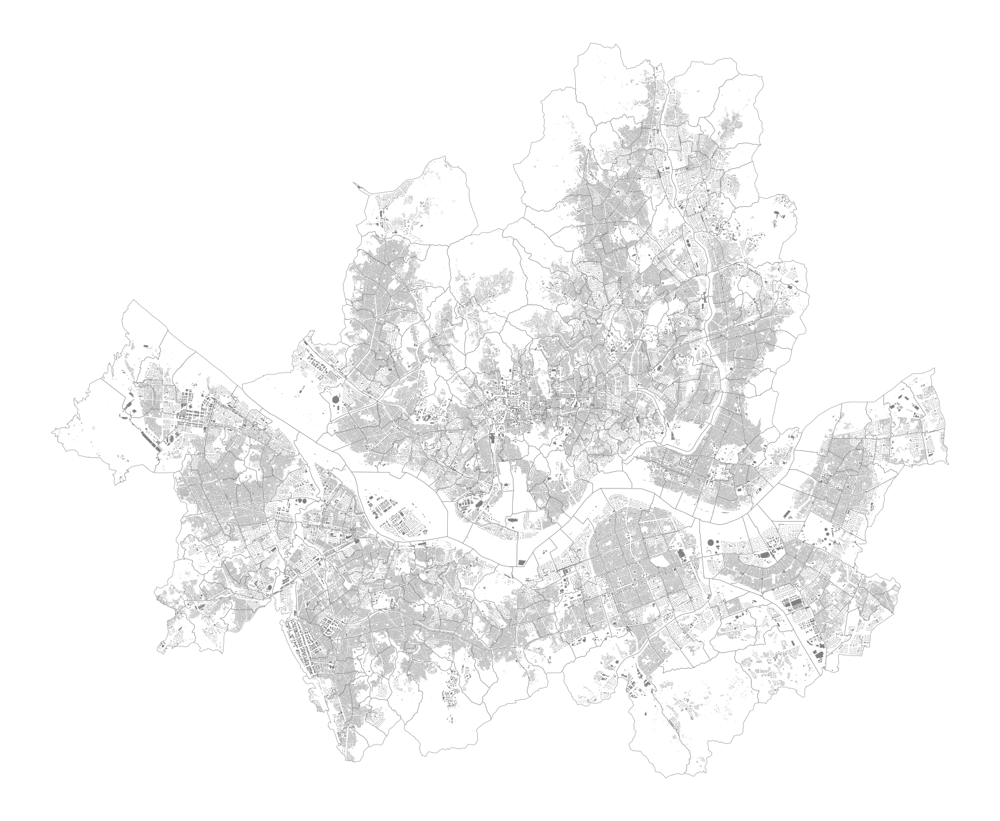

In [4]:
import matplotlib.pyplot as plt

if bldg_address.crs != bnd_dong.crs:
    bldg_address = bldg_address.to_crs(bnd_dong.crs)

ax = bnd_dong.plot(
    figsize=(20, 20),
    facecolor="white",
    edgecolor="gray",
    linewidth=0.4
)

bldg_address.plot(
    ax=ax,
    facecolor="gray",
    edgecolor="none"
)

ax.set_axis_off()
plt.show()

### 법정동 경계 및 건물

In [6]:
# 서울시 법정동 경계
adm = gpd.read_file(
    "shp/LSMD_ADM_SECT_UMD_11_202609.shp", 
    encoding="cp949"
)

print(adm.shape)
print(adm.crs)
adm

(467, 5)
EPSG:5186


,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,geometry
0,11110103,11110,궁정동,1034.0,"POLYGON ((197377.94 553847.089, 197388.365 553..."
1,11110120,11110,신문로1가,1032.0,"POLYGON ((197513.143 552250.913, 197519.052 55..."
2,11110167,11110,충신동,375.0,"POLYGON ((200756.029 553021.646, 200757.04 553..."
3,11110185,11110,홍지동,374.0,"POLYGON ((195937.08 556131.319, 195941.823 556..."
4,11110154,11110,장사동,368.0,"POLYGON ((199319.607 552274.718, 199334.592 55..."
...,...,...,...,...,...
462,11740108,11740,성내동,354.0,"POLYGON ((210911.684 548880.836, 210930.895 54..."
463,11740105,11740,길동,355.0,"POLYGON ((213293.684 549583.786, 213310.499 54..."
464,11740110,11740,강일동,377.0,"POLYGON ((214310.912 552994.432, 214359.282 55..."
465,11740101,11740,명일동,361.0,"POLYGON ((212785.854 550691.093, 212776.265 55..."


# AL_D010_11_20261009 코드북

## 데이터 개요

| 항목 | 내용 |
|---|---|
| 파일 | `AL_D010_11_20261009.shp` |
| 주제 | 서울특별시 GIS 건물통합정보 |
| 레코드 수 | 695,753개 (DBF 기준) |
| 도형 | 건물 공간도형 (폴리곤) |
| 좌표계 | EPSG:5186, Korea 2000 / Central Belt 2010 (미터) |
| 속성 인코딩 | 한글이 깨지면 GeoPandas에서 `encoding="cp949"` 지정 |

필드명은 배포 데이터의 약식 컬럼명(`A0`~`A28`)입니다. 아래 설명은 GIS 건물통합정보의 컬럼 정의를 기준으로 작성했고, 자료형과 폭은 이 파일의 DBF 헤더에서 확인했습니다.

## 속성 필드

| 필드명 | 한글명 | DBF 형식 | 설명 |
|---|---|---:|---|
| `A0` | 원천도형ID | 숫자(9) | 원천 공간자료에서 도형을 구분하는 식별값 |
| `A1` | GIS건물통합식별번호 | 문자(28) | GIS 건물통합정보의 건물 식별번호. 문자형으로 보존 |
| `A2` | 고유번호 | 문자(19) | 건축물 관련 고유번호 |
| `A3` | 법정동코드 | 문자(10) | 건물이 위치한 법정동 코드 |
| `A4` | 법정동명 | 문자(254) | 건물이 위치한 법정동 명칭 |
| `A5` | 지번 | 문자(10) | 건물의 지번 |
| `A6` | 특수지코드 | 문자(1) | 산·블록 등 특수지 여부를 구분하는 코드 |
| `A7` | 특수지구분명 | 문자(254) | 특수지코드에 해당하는 구분 명칭 |
| `A8` | 건축물용도코드 | 문자(5) | 건축물 용도 분류 코드 |
| `A9` | 건축물용도명 | 문자(254) | 건축물 용도 분류 명칭 |
| `A10` | 건축물구조코드 | 문자(2) | 건축물 구조 분류 코드 |
| `A11` | 건축물구조명 | 문자(254) | 건축물 구조 분류 명칭 |
| `A12` | 건축물면적(㎡) | 숫자(18, 소수 15자리) | 건축물 면적 |
| `A13` | 사용승인일자 | 문자(10) | 건축물 사용승인일자 |
| `A14` | 연면적(㎡) | 숫자(18, 소수 15자리) | 건축물 각 층 바닥면적의 합계 |
| `A15` | 대지면적(㎡) | 숫자(18, 소수 15자리) | 건물이 위치한 대지의 면적 |
| `A16` | 높이(m) | 숫자(18, 소수 15자리) | 건축물 높이(미터) |
| `A17` | 건폐율(%) | 숫자(18, 소수 15자리) | 대지면적 대비 건축면적의 비율 |
| `A18` | 용적률(%) | 숫자(18, 소수 15자리) | 대지면적 대비 연면적의 비율 |
| `A19` | 건축물ID | 문자(28) | 건축물 관련 연계 식별자 |
| `A20` | 위반건축물여부 | 문자(2) | 위반건축물 여부를 나타내는 코드 또는 값 |
| `A21` | 참조체계연계키 | 문자(17) | 다른 참조체계와 연계하기 위한 키 |
| `A22` | 데이터기준일자 | 날짜(8) | 데이터 기준일자 (DBF 날짜 형식) |
| `A23` | 원천시도시군구코드 | 문자(5) | 원천자료의 시·도 및 시·군·구 코드 |
| `A24` | 건물명 | 문자(254) | 건물명 |
| `A25` | 건물동명 | 문자(254) | 건물의 동 명칭 |
| `A26` | 지상층수 | 숫자(9) | 지상 층수 |
| `A27` | 지하층수 | 숫자(9) | 지하 층수 |
| `A28` | 데이터생성변경일자 | 문자(10) | 데이터 생성 또는 변경 일자 |
| `geometry` | 공간도형 | Polygon/MultiPolygon | 건물의 외곽 공간도형 |

## 사용 시 참고

- `A1`, `A2`, `A3`, `A5`, `A8` 등 식별자·코드값은 숫자처럼 보여도 문자열로 유지하세요. 선행 0이나 자릿수가 중요할 수 있습니다.
- 코드값의 상세 의미는 용도·구조·특수지 코드표와 함께 확인하세요. 코드표가 이 Shapefile에 포함되어 있지는 않습니다.
- 면적·높이·비율은 DBF에서 숫자형으로 저장되지만 소수점 15자리 형식으로 정의되어 있습니다. 분석 전에 결측값과 비현실적인 값이 있는지 확인하는 편이 좋습니다.
- `A22`는 DBF 날짜형(`D`)이며 `A28`은 문자형입니다. 두 필드의 날짜 의미와 형식은 서로 다를 수 있습니다.


## 참고 자료

- [국가교통조사·GIS 건물통합정보 데이터 항목 정의](https://www.ktdb.go.kr/DATA/pblcte/20250805093928585.pdf)
- [국토교통부 GIS 건물통합정보 관련 자료](https://www.codil.or.kr/filebank/original/RK/OTKCRK211108/OTKCRK211108.pdf)


In [6]:
bldg = gpd.read_file(
    "shp/AL_D010_11_20261009/AL_D010_11_20261009.shp",
    encoding="cp949"
)

print(bldg.shape)
print(bldg.crs)
bldg.head()

(695753, 30)
EPSG:5186


,A0,A1,A2,A3,A4,A5,A6,A7,A8,A9,...,A20,A21,A22,A23,A24,A25,A26,A27,A28,geometry
0,32,1991201839054527769900000000,1111017500107040000,1111017500,서울특별시 종로구 숭인동,704,1,일반,01000,단독주택,...,N,B00100000000T30Z9,2026-10-06,11110,NaN,NaN,3.0,0.0,2017-05-30,"POLYGON ((201913.643 553085.365, 201912.233 55..."
1,34,1967201343844527773800000000,1111017500100560024,1111017500,서울특별시 종로구 숭인동,56-24,1,일반,01000,단독주택,...,N,B00100000000T311B,2026-10-06,11110,NaN,NaN,3.0,0.0,2018-06-19,"POLYGON ((201413.763 553078.505, 201410.203 55..."
2,36,1962201375194527742000000000,1111017500100560054,1111017500,서울특별시 종로구 숭인동,56-54,1,일반,01000,단독주택,...,N,B00100000000T313D,2026-10-06,11110,NaN,NaN,2.0,0.0,2017-02-24,"POLYGON ((201442.603 553075.746, 201442.303 55..."
3,37,1979201388484527710100000000,1111017500100560053,1111017500,서울특별시 종로구 숭인동,56-53,1,일반,01000,단독주택,...,N,B00100000000T314E,2026-10-06,11110,NaN,NaN,2.0,1.0,2018-11-06,"POLYGON ((201458.573 553069.445, 201453.553 55..."
4,38,0000200468294527764000000000,1111016500100280011,1111016500,서울특별시 종로구 이화동,28-11,1,일반,NaN,NaN,...,NaN,B00100000000T315F,2026-10-06,11110,NaN,NaN,0.0,0.0,NaN,"POLYGON ((200540.543 553080.585, 200536.443 55..."


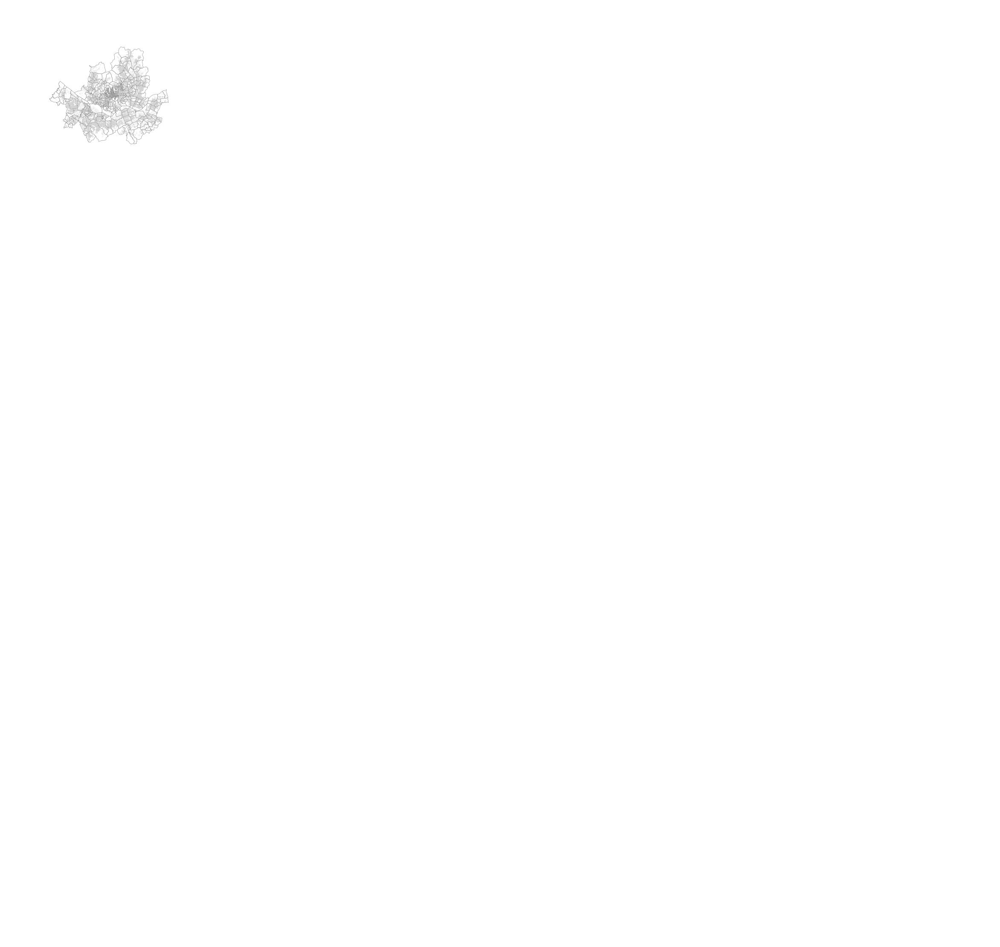

In [7]:
import matplotlib.pyplot as plt

if adm.crs != bldg.crs:
    bldg = bldg.to_crs(adm.crs)

ax = adm.plot(
    figsize=(30, 30),
    facecolor="white",
    edgecolor="gray",
    linewidth=0.4
)

bldg.plot(
    ax=ax,
    facecolor="lightgray",
    edgecolor="none"
)

ax.set_axis_off()
plt.show()

In [8]:
# bldg 범위의 남쪽 끝이 301293으로 adm의 536547보다 훨씬 멀리 떨어져있음 
print("adm bounds:", adm.total_bounds)
print("bldg bounds:", bldg.total_bounds)
print(adm.crs, bldg.crs)

adm bounds: [179189.73694329 536547.41820785 216242.25284494 566863.54429778]
bldg bounds: [179468.03291913 301293.65894871 459564.96094115 566616.34548084]
EPSG:5186 EPSG:5186


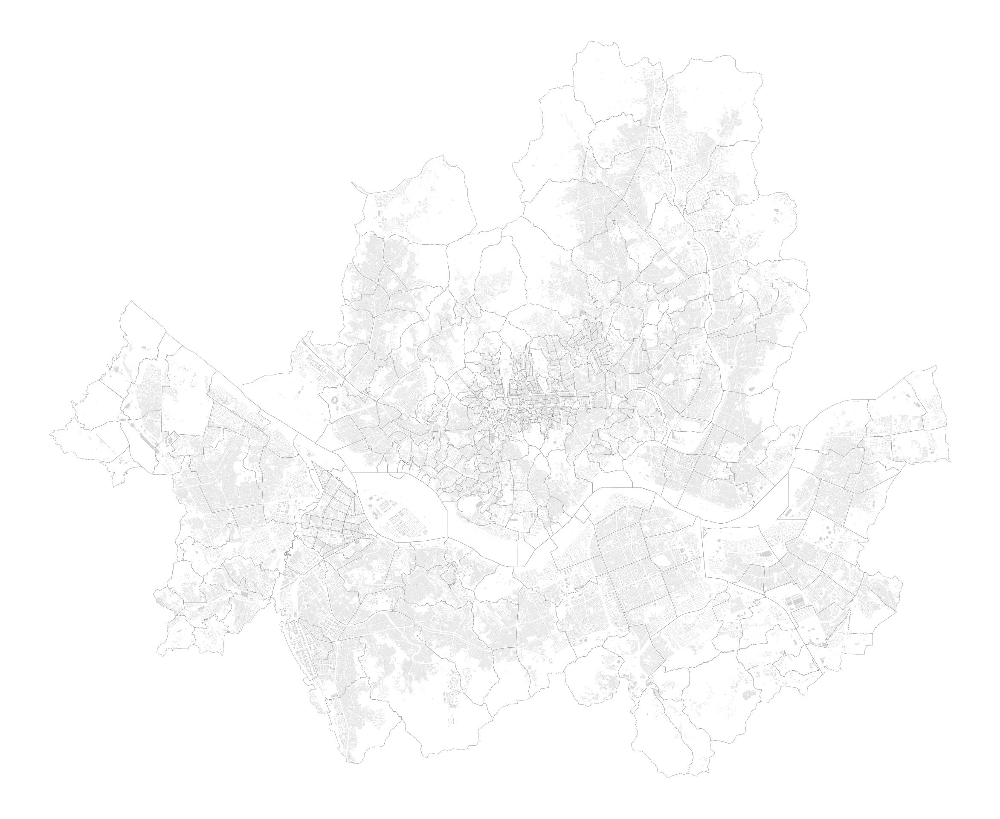

In [9]:
# adm의 경계 상자와 겹치는 bldg만 선택
minx, miny, maxx, maxy = adm.total_bounds
bldg_view = bldg.cx[minx:maxx, miny:maxy]

ax = adm.plot(
    figsize=(30, 30),
    facecolor="white",
    edgecolor="gray",
    linewidth=0.4
)

bldg_view.plot(
    ax=ax,
    facecolor="lightgray",
    edgecolor="none"
)

ax.set_axis_off()
plt.show()

## 1. 법정동별 건축 밀도 산정 
- 법정동 면적 산정 (sqkm)
- 법정동별 건축물 연면적 총합 산정
- 법정동별 대지면적 총합 산정
- 총 건축밀도 = 총 연면적 / 법정동 면적
- 순 건축밀도 = 총 연면적 / 총 대지면적

In [10]:
# 법정동 면적 산정 (sqm)
adm["dong_area"] = adm.area # area in square meters
adm.head()

,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,geometry,dong_area
0,11110103,11110,궁정동,1034.0,"POLYGON ((197377.94 553847.089, 197388.365 553...",73324.952123
1,11110120,11110,신문로1가,1032.0,"POLYGON ((197513.143 552250.913, 197519.052 55...",65766.008004
2,11110167,11110,충신동,375.0,"POLYGON ((200756.029 553021.646, 200757.04 553...",128234.135423
3,11110185,11110,홍지동,374.0,"POLYGON ((195937.08 556131.319, 195941.823 556...",355829.148199
4,11110154,11110,장사동,368.0,"POLYGON ((199319.607 552274.718, 199334.592 55...",57633.998132


In [11]:
bldg.columns

Index(['A0', 'A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10',
       'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20',
       'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'geometry'],
      dtype='str')

In [12]:
# 도형 면적(㎡) * 층수로 계산
bldg["area_sqm"] = bldg.geometry.area
bldg["bldg_area_geometry"] =  bldg["area_sqm"] * bldg["A26"]  

# A14(연면적) 컬럼 이름 변경
bldg = bldg.rename(columns={"A14": "bldg_area"})

# A15(대지면적) 컬럼 이름 변경
bldg = bldg.rename(columns={"A15": "land_area"})

bldg[["bldg_area", "bldg_area_geometry"]].head() # bldg_area 사용

,bldg_area,bldg_area_geometry
0,203.13,207.332600
1,114.98,205.378281
2,135.20,182.588305
3,230.18,251.312847
4,0.00,0.000000


In [13]:
adm

,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,geometry,dong_area
0,11110103,11110,궁정동,1034.0,"POLYGON ((197377.94 553847.089, 197388.365 553...",7.332495e+04
1,11110120,11110,신문로1가,1032.0,"POLYGON ((197513.143 552250.913, 197519.052 55...",6.576601e+04
2,11110167,11110,충신동,375.0,"POLYGON ((200756.029 553021.646, 200757.04 553...",1.282341e+05
3,11110185,11110,홍지동,374.0,"POLYGON ((195937.08 556131.319, 195941.823 556...",3.558291e+05
4,11110154,11110,장사동,368.0,"POLYGON ((199319.607 552274.718, 199334.592 55...",5.763400e+04
...,...,...,...,...,...,...
462,11740108,11740,성내동,354.0,"POLYGON ((210911.684 548880.836, 210930.895 54...",1.957705e+06
463,11740105,11740,길동,355.0,"POLYGON ((213293.684 549583.786, 213310.499 54...",1.612791e+06
464,11740110,11740,강일동,377.0,"POLYGON ((214310.912 552994.432, 214359.282 55...",2.267709e+06
465,11740101,11740,명일동,361.0,"POLYGON ((212785.854 550691.093, 212776.265 55...",1.572132e+06


In [14]:
adm.query("EMD_NM == '청운동'")[["EMD_CD", "dong_area"]]

,EMD_CD,dong_area
66,11110101,793213.771395


In [15]:
# 법정동별 연면적 총합 산정
bldg = bldg.rename(columns={"A3": "adm_cd"}) # 법정동 코드 컬럼 이름 변경
bldg = bldg.rename(columns={"A4": "adm_nm"}) # 법정동 이름 컬럼 이름 변경


bldg_adm = bldg.groupby(["adm_cd", "adm_nm"])[["bldg_area",'land_area']].sum().reset_index()
bldg_adm

,adm_cd,adm_nm,bldg_area,land_area
0,1111010100,서울특별시 종로구 청운동,2.280075e+05,1.008754e+05
1,1111010200,서울특별시 종로구 신교동,1.566300e+05,7.189318e+04
2,1111010300,서울특별시 종로구 궁정동,8.629090e+03,6.008450e+03
3,1111010400,서울특별시 종로구 효자동,4.011103e+04,1.355357e+04
4,1111010500,서울특별시 종로구 창성동,6.971987e+04,6.882325e+04
...,...,...,...,...
462,1174010600,서울특별시 강동구 둔촌동,1.283652e+06,7.734057e+05
463,1174010700,서울특별시 강동구 암사동,2.475660e+06,6.219470e+05
464,1174010800,서울특별시 강동구 성내동,3.207616e+06,9.973276e+05
465,1174010900,서울특별시 강동구 천호동,3.683632e+06,1.117281e+06


In [16]:
adm["EMD_CD"] = adm["EMD_CD"].astype(str) + "00" # 10자리로 맞춤
adm

,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,geometry,dong_area
0,1111010300,11110,궁정동,1034.0,"POLYGON ((197377.94 553847.089, 197388.365 553...",7.332495e+04
1,1111012000,11110,신문로1가,1032.0,"POLYGON ((197513.143 552250.913, 197519.052 55...",6.576601e+04
2,1111016700,11110,충신동,375.0,"POLYGON ((200756.029 553021.646, 200757.04 553...",1.282341e+05
3,1111018500,11110,홍지동,374.0,"POLYGON ((195937.08 556131.319, 195941.823 556...",3.558291e+05
4,1111015400,11110,장사동,368.0,"POLYGON ((199319.607 552274.718, 199334.592 55...",5.763400e+04
...,...,...,...,...,...,...
462,1174010800,11740,성내동,354.0,"POLYGON ((210911.684 548880.836, 210930.895 54...",1.957705e+06
463,1174010500,11740,길동,355.0,"POLYGON ((213293.684 549583.786, 213310.499 54...",1.612791e+06
464,1174011000,11740,강일동,377.0,"POLYGON ((214310.912 552994.432, 214359.282 55...",2.267709e+06
465,1174010100,11740,명일동,361.0,"POLYGON ((212785.854 550691.093, 212776.265 55...",1.572132e+06


In [17]:
# adm, bldg_adm 조인

adm_bldg = adm.merge(
    bldg_adm,
    left_on="EMD_CD",
    right_on="adm_cd",
    how="left"
)

adm_bldg.head()

,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,geometry,dong_area,adm_cd,adm_nm,bldg_area,land_area
0,1111010300,11110,궁정동,1034.0,"POLYGON ((197377.94 553847.089, 197388.365 553...",73324.952123,1111010300,서울특별시 종로구 궁정동,8629.09,6008.450
1,1111012000,11110,신문로1가,1032.0,"POLYGON ((197513.143 552250.913, 197519.052 55...",65766.008004,1111012000,서울특별시 종로구 신문로1가,284311.72,23591.828
2,1111016700,11110,충신동,375.0,"POLYGON ((200756.029 553021.646, 200757.04 553...",128234.135423,1111016700,서울특별시 종로구 충신동,156941.13,43086.270
3,1111018500,11110,홍지동,374.0,"POLYGON ((195937.08 556131.319, 195941.823 556...",355829.148199,1111018500,서울특별시 종로구 홍지동,179910.30,874451.496
4,1111015400,11110,장사동,368.0,"POLYGON ((199319.607 552274.718, 199334.592 55...",57633.998132,1111015400,서울특별시 종로구 장사동,66041.29,3873.650


In [18]:
adm_bldg.count()


EMD_CD        467
COL_ADM_SE    467
EMD_NM        467
SGG_OID       467
geometry      467
dong_area     467
adm_cd        467
adm_nm        467
bldg_area     467
land_area     467
dtype: int64

In [19]:
# 총 건축밀도 = 총 연면적 / 법정동 면적
adm_bldg["tot_density"] = adm_bldg["bldg_area"] / adm_bldg["dong_area"]


# 순 건축밀도 = 총 연면적 / 총 대지면적
adm_bldg["net_density"] = adm_bldg["bldg_area"] / adm_bldg["land_area"]

adm_bldg

,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,geometry,dong_area,adm_cd,adm_nm,bldg_area,land_area,tot_density,net_density
0,1111010300,11110,궁정동,1034.0,"POLYGON ((197377.94 553847.089, 197388.365 553...",7.332495e+04,1111010300,서울특별시 종로구 궁정동,8.629090e+03,6008.4500,0.117683,1.436159
1,1111012000,11110,신문로1가,1032.0,"POLYGON ((197513.143 552250.913, 197519.052 55...",6.576601e+04,1111012000,서울특별시 종로구 신문로1가,2.843117e+05,23591.8280,4.323080,12.051280
2,1111016700,11110,충신동,375.0,"POLYGON ((200756.029 553021.646, 200757.04 553...",1.282341e+05,1111016700,서울특별시 종로구 충신동,1.569411e+05,43086.2700,1.223864,3.642486
3,1111018500,11110,홍지동,374.0,"POLYGON ((195937.08 556131.319, 195941.823 556...",3.558291e+05,1111018500,서울특별시 종로구 홍지동,1.799103e+05,874451.4960,0.505609,0.205741
4,1111015400,11110,장사동,368.0,"POLYGON ((199319.607 552274.718, 199334.592 55...",5.763400e+04,1111015400,서울특별시 종로구 장사동,6.604129e+04,3873.6500,1.145874,17.048853
...,...,...,...,...,...,...,...,...,...,...,...,...
462,1174010800,11740,성내동,354.0,"POLYGON ((210911.684 548880.836, 210930.895 54...",1.957705e+06,1174010800,서울특별시 강동구 성내동,3.207616e+06,997327.5874,1.638457,3.216211
463,1174010500,11740,길동,355.0,"POLYGON ((213293.684 549583.786, 213310.499 54...",1.612791e+06,1174010500,서울특별시 강동구 길동,2.196927e+06,766700.1450,1.362189,2.865431
464,1174011000,11740,강일동,377.0,"POLYGON ((214310.912 552994.432, 214359.282 55...",2.267709e+06,1174011000,서울특별시 강동구 강일동,8.167126e+05,68492.6600,0.360149,11.924090
465,1174010100,11740,명일동,361.0,"POLYGON ((212785.854 550691.093, 212776.265 55...",1.572132e+06,1174010100,서울특별시 강동구 명일동,1.943576e+06,276758.2050,1.236268,7.022652


d:\Dropbox\0_Classes\5_스마트도시데이터분석\.venv\Lib\site-packages\mapclassify\classifiers.py:942: RuntimeWarning: invalid value encountered in subtract
  css = yc - yc.mean()
d:\Dropbox\0_Classes\5_스마트도시데이터분석\.venv\Lib\site-packages\mapclassify\classifiers.py:972: RuntimeWarning: invalid value encountered in scalar divide
  gadf = 1 if adam == 0 else 1 - self.adcm / adam


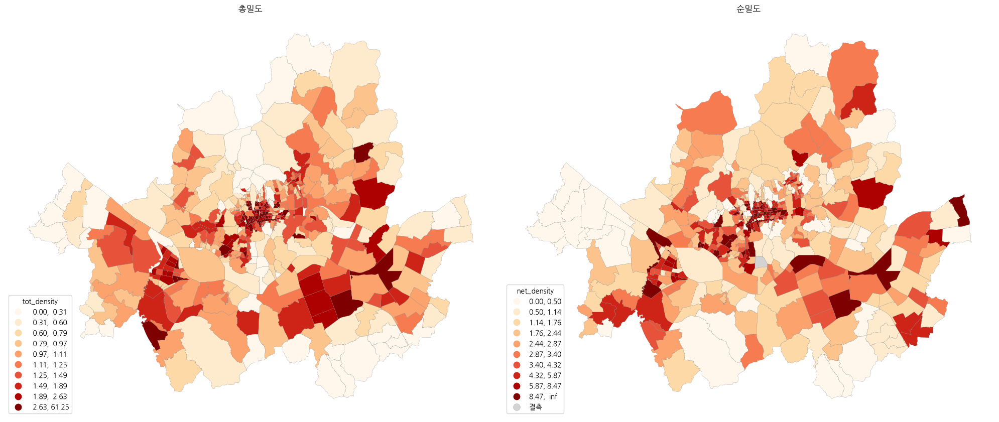

In [20]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

for ax, col, title in zip(
    axes,
    ["tot_density", "net_density"],
    ["총밀도", "순밀도"]
):
    adm_bldg.plot(
        column=col,
        scheme="Quantiles",
        k=10,
        cmap="OrRd",
        linewidth=0.2,
        edgecolor="gray",
        legend=True,
        ax=ax,
        missing_kwds={
            "color": "lightgray",
            "label": "결측"
        },
        legend_kwds={"title": col, "loc": "lower left"}
    )
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## 토지이용 혼합도

# UPIS_C_UQ111 코드북

## 데이터 개요

| 항목 | 내용 |
|---|---|
| 파일 | `UPIS_C_UQ111.shp` |
| 주제 | 도시지역 용도지역 현황 공간자료 |
| 레코드 수 | 8,334개 (DBF 기준) |
| 도형 | 면(Polygon/MultiPolygon) |
| 좌표계 | EPSG:5174, Korean 1985 / Modified Korea Central Belt (미터) |
| 속성 인코딩 | 한글이 깨지면 `encoding="cp949"` 또는 `encoding="euc-kr"`로 읽기 |

필드명과 자료형은 동봉된 DBF에서 확인했습니다. 설명은 UPIS 도시계획 공간자료의 항목 정의를 기준으로 정리했습니다. 코드값별 용도지역 세부 명칭은 `레이어표_111.xlsx` 등 배포 자료의 코드표와 대조하세요.

## 속성 필드

| 필드명 | 한글명 | DBF 형식 | 설명 |
|---|---|---:|---|
| `PRESENT_SN` | 현황도형 관리번호 | 문자(50) | 현황 공간도형의 관리 식별번호 |
| `LCLAS_CL` | 도형 대분류코드 | 문자(6) | 도시계획 도형의 대분류 코드 |
| `MLSFC_CL` | 도형 중분류코드 | 문자(6) | 도시계획 도형의 중분류 코드 |
| `SCLAS_CL` | 도형 소분류코드 | 문자(12) | 도시계획 도형의 소분류 코드 |
| `ATRB_SE` | 도형 속성코드 | 문자(6) | 도형의 속성 구분 코드 |
| `WTNNC_SN` | 도형 조서관리 코드 | 문자(20) | 관련 조서 또는 관리자료의 식별번호 |
| `NTFC_SN` | 결정고시관리 코드 | 문자(20) | 용도지역 결정·고시 자료의 관리 식별번호 |
| `DGM_NM` | 라벨명 | 문자(200) | 지도 표시 및 속성 확인에 사용하는 도형 명칭 |
| `DGM_AR` | 면적(도형) | 숫자(19, 소수 8자리) | 도형에 기록된 면적 값. 단위와 산정 기준은 배포 자료 메타데이터 확인 권장 |
| `DGM_LT` | 길이(도형) | 숫자(19, 소수 8자리) | 도형에 기록된 길이 값. 면 자료에서는 보통 경계 길이 관련 값 |
| `SIGNGU_SE` | 시군구코드 | 문자(5) | 해당 도형의 시군구 코드 |
| `DRAWING_NO` | 도면번호 | 문자(254) | 도형이 수록된 도시계획 도면 식별번호 |
| `CREATE_DAT` | 현황도형 생성일자 | 날짜(8) | 도형 레코드 생성일자 (DBF 날짜형) |
| `SHAPE_AREA` | 공간도형 면적 | 실수(19, 소수 11자리) | GIS 소프트웨어가 계산·저장한 도형 면적. 좌표계 단위 기준으로 해석 |
| `SHAPE_LEN` | 공간도형 둘레 길이 | 실수(19, 소수 11자리) | GIS 소프트웨어가 계산·저장한 도형 둘레 길이. 좌표계 단위 기준으로 해석 |
| `geometry` | 공간도형 | Polygon/MultiPolygon | 용도지역 경계 도형 |

## 코드 및 면적 사용 참고

- `LCLAS_CL`, `MLSFC_CL`, `SCLAS_CL`, `ATRB_SE`는 코드 필드입니다. 표시 이름을 만들 때는 제공처 코드표를 이용해 조인하세요.
- `DGM_NM`은 라벨용 이름이므로 분석 분류 기준으로 쓸 때 코드 필드와 함께 교차 확인하세요.
- `DGM_AR`와 `SHAPE_AREA`는 출처와 계산 방식이 다를 수 있습니다. 직접 면적을 산출할 때는 CRS가 미터 단위인지 확인한 뒤 `geometry.area`를 계산하고, 제공 속성 면적과 비교하세요.
- 이 레이어의 CRS는 EPSG:5174입니다. 다른 CRS의 레이어와 중첩·조인하기 전에는 한쪽을 `to_crs()`로 변환하세요.
- 코드/식별자는 문자열로 유지하세요. 숫자로 바꾸면 선행 0이 사라질 수 있습니다.

```

## 참고 자료

- [도시계획정보시스템 공간자료 항목 정의 예시](https://www.codil.or.kr/filebank/original/RK/OTKCRK230259/OTKCRK230259.pdf)
- 동봉 파일 `레이어표_111.xlsx` — 제공된 레이어·코드 설명표


In [21]:
landuse = gpd.read_file(
    "shp/569_UQ111_용도지역(도시지역)_202609/UPIS_C_UQ111.shp"
)

print(landuse.shape)
print(landuse.crs)
landuse.head()

(8334, 16)
EPSG:5174


,PRESENT_SN,LCLAS_CL,MLSFC_CL,SCLAS_CL,ATRB_SE,WTNNC_SN,NTFC_SN,DGM_NM,DGM_AR,DGM_LT,SIGNGU_SE,DRAWING_NO,CREATE_DAT,SHAPE_AREA,SHAPE_LEN,geometry
0,11000UQ111PS201912154568,UQA100,UQA120,UQA122,UQA122,11000ARZ000000001111,NaN,제2종일반주거지역,382485.842659,4271.535769,11000,NaN,2019-12-15,382485.842658,4271.535769,"POLYGON ((202377.279 446904.199, 202374.3 4468..."
1,11000UQ111PS202011120006,UQA100,UQA120,UQA122,UQA122,11140ARZ201912050001,11000NTC202007290001,제2종일반주거지역,448.922280,126.550361,11000,NaN,2020-11-12,448.921455,126.550280,"POLYGON ((202174.299 451339.194, 202174.951 45..."
2,11000UQ111PS202102030001,UQA200,UQA220,NaN,UQA220,11000ARZ202102010002,11000NTC202102010004,일반상업지역,2375.300602,204.828046,11000,NaN,2021-02-03,2375.300807,204.828046,"POLYGON ((204794.215 463546.697, 204797.103 46..."
3,11000UQ111PS201912156263,UQA400,UQA430,NaN,UQA430,11000ARZ000000001111,NaN,자연녹지지역,366281.337850,8977.360668,11000,NaN,2019-12-15,366281.337625,8977.360638,"POLYGON ((189290.93 449728.939, 189301.379 449..."
4,11000UQ111PS201912155856,UQA200,UQA220,NaN,UQA220,11000ARZ000000001111,NaN,일반상업지역,14537.864382,2389.678869,11000,NaN,2019-12-15,14537.864379,2389.678862,"POLYGON ((195960.683 449191.643, 195959.839 44..."


In [22]:
landuse.DGM_NM.unique()

<StringArray>
[          '제2종일반주거지역',              '일반상업지역',              '자연녹지지역',
           '제3종일반주거지역',               '준주거지역',    '제2종일반주거지역(12층이하)',
     '제2종일반주거지역(7층이하)',           '제1종일반주거지역',           '제1종전용주거지역',
               '준공업지역',             '기타 도시지역',          '전용주거지역 미분류',
      '제2종일반주거지역(12층)',              '근린상업지역',    '제1-1지구 제2종일반주거지역',
              '유통상업지역',              '생산녹지지역',       '제2종일반주거지역(7층)',
        '2종일반주거지역(7층)',         '제2종일반주거(7층)',           '제2종전용주거지역',
      '2종일반주거지역(7층이하)',      '제2일반주거지역(7층이하)',            '1종일반주거지역',
     '제2종(7층이하)일반주거지역',           '제2종7층일반주거',    '제2종일반주거지역(7층 이하)',
     '제2종일반주거지역(7충이하)',     '흑석3구역-제1종일반주거지역',              '보전녹지지역',
              '일반주거지역',            '2종일반주거지역',            '일반주거지역기타',
         '제2종일반주거지역7층',              '자역녹지지역',    '녹번 제1-2지구 자연녹지지역',
              '사회복지시설',              '중심상업지역',     '2종일반주거지역(12층이하)',
           '재2종일반주거지역',        '제2종일반주거(12층)',          '제3종 일반주거지역',
     '

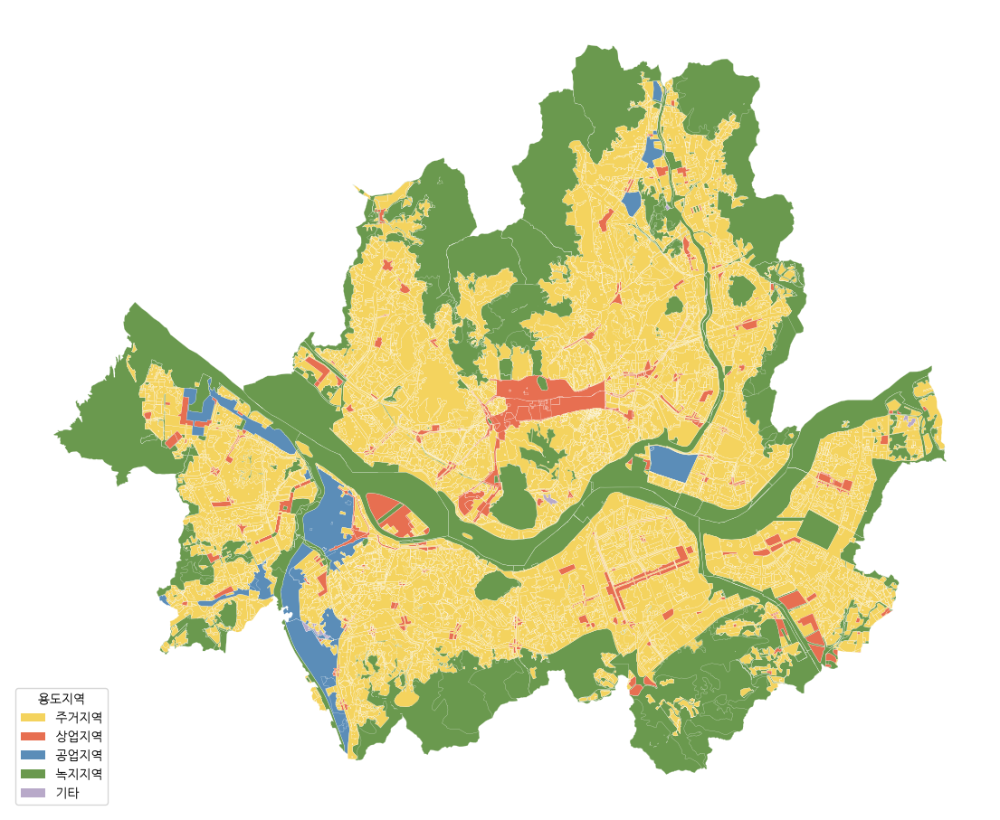

In [23]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def zone_color(name):
    name = str(name)

    if "주거지역" in name:
        return "#F4D35E"  # 노란색 계열
    elif "상업지역" in name:
        return "#E76F51"  # 빨간색 계열
    elif "공업지역" in name:
        return "#5B8DB8"  # 파란색 계열
    elif "녹지지역" in name:
        return "#6A994E"  # 녹색 계열
    else:
        return "#B8A9C9"  # 그 외 용도지역은 연보라색

landuse["map_color"] = landuse["DGM_NM"].apply(zone_color)

fig, ax = plt.subplots(figsize=(14, 14))

landuse.plot(
    color=landuse["map_color"],
    edgecolor="white",
    linewidth=0.15,
    ax=ax
)

legend_items = [
    Patch(facecolor="#F4D35E", label="주거지역"),
    Patch(facecolor="#E76F51", label="상업지역"),
    Patch(facecolor="#5B8DB8", label="공업지역"),
    Patch(facecolor="#6A994E", label="녹지지역"),
    Patch(facecolor="#B8A9C9", label="기타")
]

ax.legend(handles=legend_items, title="용도지역", loc="lower left")
ax.set_axis_off()
plt.show()

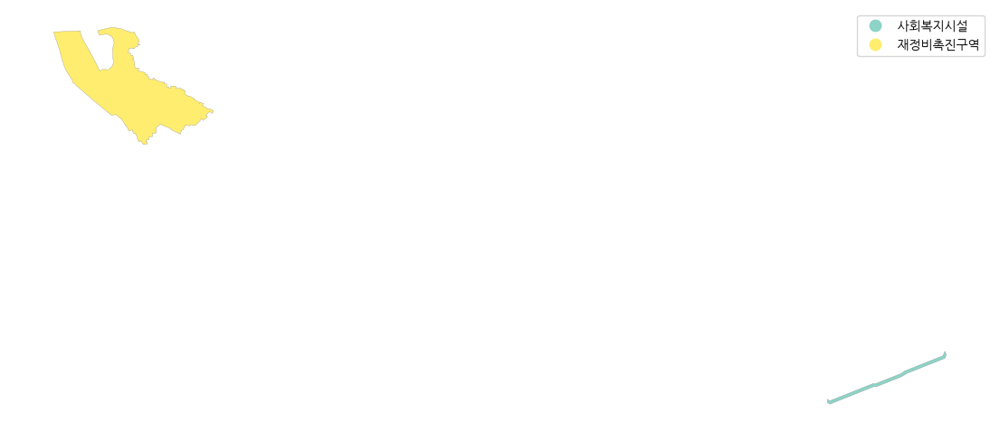

In [24]:
mask = landuse["DGM_NM"].astype(str).str.endswith(("시설", "구역"))
landuse_selected = landuse.loc[mask].copy()

fig, ax = plt.subplots(figsize=(14, 14))

landuse_selected.plot(
    ax=ax,
    column="DGM_NM",
    categorical=True,
    cmap="Set3",
    legend=True,
    edgecolor="gray",
    linewidth=0.2
)

ax.set_axis_off()
plt.show()

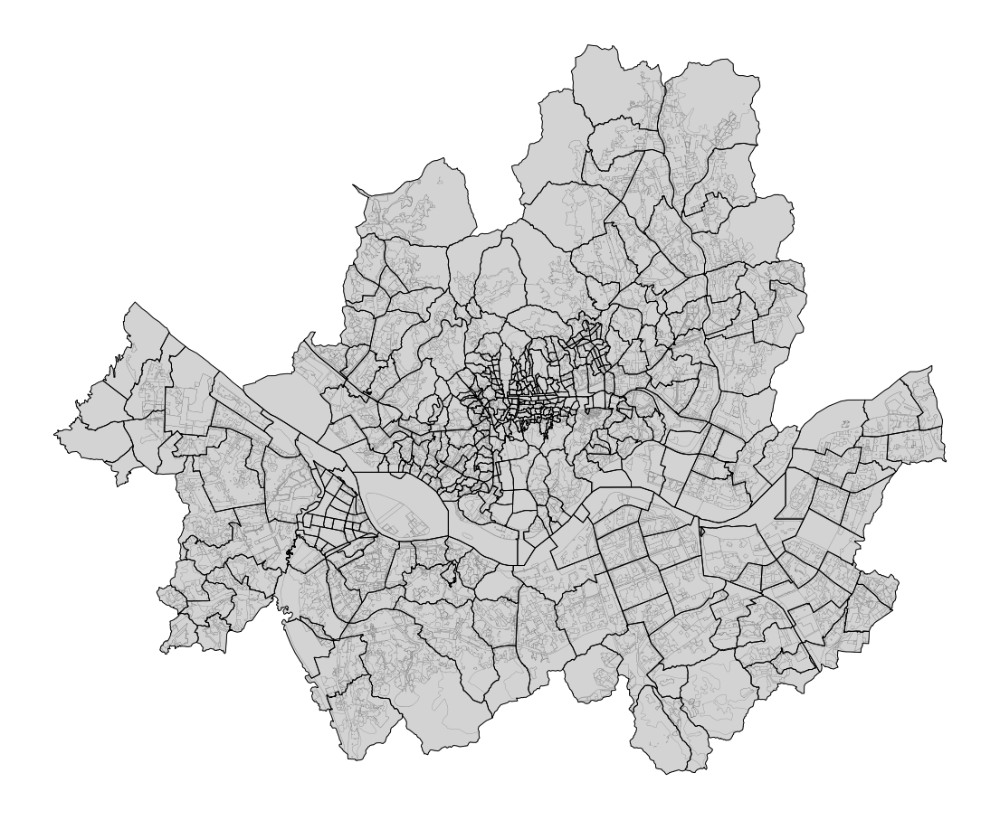

In [25]:
import matplotlib.pyplot as plt

adm_plot = adm.to_crs(landuse.crs) if adm.crs != landuse.crs else adm

fig, ax = plt.subplots(figsize=(14, 14))

landuse.plot(
    ax=ax,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.2
)

adm_plot.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.7,
    zorder=2
)

ax.set_axis_off()
plt.show()

In [26]:
# 법정동 경계로 landuse 자르기
import geopandas as gpd

if adm.crs != landuse.crs:
    landuse = landuse.to_crs(adm.crs)

adm_landuse = gpd.overlay(
    adm,
    landuse,
    how="intersection"
)

print(adm_landuse.shape)
adm_landuse.head()

(13117, 22)


d:\Dropbox\0_Classes\5_스마트도시데이터분석\.venv\Lib\site-packages\geopandas\tools\overlay.py:375: UserWarning: `keep_geom_type=True` in overlay resulted in 5324 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,dong_area,PRESENT_SN,LCLAS_CL,MLSFC_CL,SCLAS_CL,ATRB_SE,...,DGM_NM,DGM_AR,DGM_LT,SIGNGU_SE,DRAWING_NO,CREATE_DAT,SHAPE_AREA,SHAPE_LEN,map_color,geometry
0,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS201905210030,UQA400,UQA430,NaN,UQA430,...,자연녹지지역,1.089063e+07,55507.041578,11000,NaN,2019-05-24,1.089063e+07,55507.037772,#6A994E,"MULTIPOLYGON (((197606.241 554038.354, 197612...."
1,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS201912151136,UQA100,UQA120,UQA121,UQA121,...,제1종일반주거지역,7.131335e+05,10310.535809,11000,NaN,2019-12-15,7.131335e+05,10310.535809,#F4D35E,"MULTIPOLYGON (((197516.978 553922.301, 197517...."
2,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS202509030002,UQA400,UQA430,NaN,UQA430,...,자연녹지지역,4.942135e+07,385853.237280,11000,NaN,2025-09-03,4.942135e+07,385853.236305,#6A994E,"POLYGON ((197606.241 554038.354, 197612.374 55..."
3,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS201912151485,UQA100,UQA120,UQA124,UQA124,...,제2종일반주거지역(7층이하),5.826209e+05,6061.798528,11000,NaN,2019-12-15,5.826209e+05,6061.798528,#F4D35E,"MULTIPOLYGON (((197388.365 553851.258, 197397...."
4,1111012000,11110,신문로1가,1032.0,65766.008004,11000UQ111PS201912154076,UQA100,UQA120,UQA123,UQA123,...,제3종일반주거지역,1.803588e+04,967.583187,11000,NaN,2019-12-15,1.803588e+04,967.583187,#F4D35E,"POLYGON ((197530.043 552326.189, 197527.628 55..."


In [27]:
# SHAPE_AREA 재산정 : 잘려진 폴리곤 면적 다시 계산
adm_landuse["SHAPE_AREA"] = adm_landuse.geometry.area
adm_landuse.head()

,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,dong_area,PRESENT_SN,LCLAS_CL,MLSFC_CL,SCLAS_CL,ATRB_SE,...,DGM_NM,DGM_AR,DGM_LT,SIGNGU_SE,DRAWING_NO,CREATE_DAT,SHAPE_AREA,SHAPE_LEN,map_color,geometry
0,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS201905210030,UQA400,UQA430,NaN,UQA430,...,자연녹지지역,1.089063e+07,55507.041578,11000,NaN,2019-05-24,22811.721686,55507.037772,#6A994E,"MULTIPOLYGON (((197606.241 554038.354, 197612...."
1,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS201912151136,UQA100,UQA120,UQA121,UQA121,...,제1종일반주거지역,7.131335e+05,10310.535809,11000,NaN,2019-12-15,24503.386314,10310.535809,#F4D35E,"MULTIPOLYGON (((197516.978 553922.301, 197517...."
2,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS202509030002,UQA400,UQA430,NaN,UQA430,...,자연녹지지역,4.942135e+07,385853.237280,11000,NaN,2025-09-03,22485.147791,385853.236305,#6A994E,"POLYGON ((197606.241 554038.354, 197612.374 55..."
3,1111010300,11110,궁정동,1034.0,73324.952123,11000UQ111PS201912151485,UQA100,UQA120,UQA124,UQA124,...,제2종일반주거지역(7층이하),5.826209e+05,6061.798528,11000,NaN,2019-12-15,26009.690037,6061.798528,#F4D35E,"MULTIPOLYGON (((197388.365 553851.258, 197397...."
4,1111012000,11110,신문로1가,1032.0,65766.008004,11000UQ111PS201912154076,UQA100,UQA120,UQA123,UQA123,...,제3종일반주거지역,1.803588e+04,967.583187,11000,NaN,2019-12-15,2871.087178,967.583187,#F4D35E,"POLYGON ((197530.043 552326.189, 197527.628 55..."


In [28]:
adm_landuse.query("EMD_NM == '통인동'")[["EMD_CD","EMD_NM","DGM_NM", "SHAPE_AREA"]]

,EMD_CD,EMD_NM,DGM_NM,SHAPE_AREA
503,1111010800,통인동,제2종일반주거지역(7층이하),50073.58148


In [29]:
import numpy as np
import pandas as pd

adm_landuse["SHAPE_AREA"] = adm_landuse.geometry.area

# SHAPE_AREA가 교차 후 조각의 면적이어야 합니다.
area_by_use = (
    adm_landuse
    .dropna(subset=["EMD_CD", "EMD_NM", "DGM_NM", "SHAPE_AREA"])
    .loc[lambda df: df["SHAPE_AREA"] > 0]
    .groupby(["EMD_CD", "EMD_NM", "DGM_NM"], as_index=False)["SHAPE_AREA"]
    .sum()
)

area_by_use["p"] = (
    area_by_use["SHAPE_AREA"]
    / area_by_use.groupby("EMD_CD")["SHAPE_AREA"].transform("sum")
)

# 동별 Shannon entropy: -Σ(p * ln(p))
entropy = (
    area_by_use.assign(p_log_p=lambda df: df["p"] * np.log(df["p"]))
    .groupby(["EMD_CD", "EMD_NM"], as_index=False)["p_log_p"]
    .sum()
    .rename(columns={"p_log_p": "entropy"})
)
entropy["entropy"] *= -1

entropy

,EMD_CD,EMD_NM,entropy
0,1111010100,청운동,0.684621
1,1111010200,신교동,0.998931
2,1111010300,궁정동,1.056872
3,1111010400,효자동,0.198552
4,1111010500,창성동,0.382594
...,...,...,...
462,1174010600,둔촌동,1.453771
463,1174010700,암사동,1.034520
464,1174010800,성내동,1.349196
465,1174010900,천호동,1.870000


In [30]:
import numpy as np
import pandas as pd

# SHAPE_AREA가 교차 후 조각의 면적이어야 합니다.
area_by_use = (
    adm_landuse
    .dropna(subset=["EMD_CD", "EMD_NM", "DGM_NM", "SHAPE_AREA"])
    .loc[lambda df: df["SHAPE_AREA"] > 0]
    .groupby(["EMD_CD", "EMD_NM", "DGM_NM"], as_index=False)["SHAPE_AREA"]
    .sum()
)

area_by_use["p"] = (
    area_by_use["SHAPE_AREA"]
    / area_by_use.groupby("EMD_CD")["SHAPE_AREA"].transform("sum")
)

# 동별 Shannon entropy: -Σ(p * ln(p))
entropy = (
    area_by_use.assign(p_log_p=lambda df: df["p"] * np.log(df["p"]))
    .groupby(["EMD_CD", "EMD_NM"], as_index=False)["p_log_p"]
    .sum()
    .rename(columns={"p_log_p": "entropy"})
)
entropy["entropy"] *= -1

# 전체 데이터에 있는 용도지역 종류 수를 기준으로 0~1 정규화
n_uses = area_by_use["DGM_NM"].nunique()
entropy["entropy_norm"] = (
    entropy["entropy"] / np.log(n_uses) if n_uses > 1 else 0
)

entropy.sort_values("entropy_norm", ascending=False)

,EMD_CD,EMD_NM,entropy,entropy_norm
190,1117013000,이태원동,2.099829,0.501194
295,1138010700,응암동,2.039176,0.486717
255,1129011900,동선동4가,1.979114,0.472381
230,1123011000,이문동,1.963118,0.468563
232,1126010200,상봉동,1.959342,0.467662
...,...,...,...,...
25,1111012600,종로1가,-0.000000,-0.000000
26,1111012700,공평동,-0.000000,-0.000000
27,1111012800,관훈동,-0.000000,-0.000000
28,1111012900,견지동,-0.000000,-0.000000


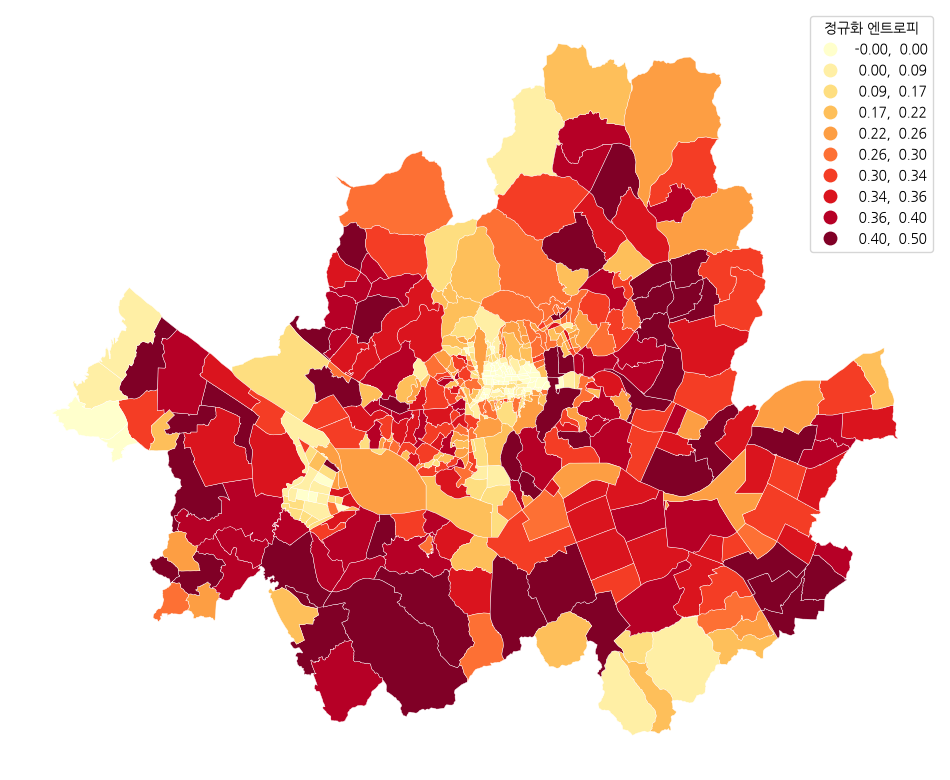

In [31]:
# entropy 결과를 행정동 경계에 결합
adm_entropy = adm.merge(
    entropy[["EMD_CD", "entropy_norm"]],
    on="EMD_CD",
    how="left"
)

fig, ax = plt.subplots(figsize=(12, 12))

adm_entropy.plot(
    column="entropy_norm",
    scheme="Quantiles",
    k=10,
    cmap="YlOrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    missing_kwds={
        "color": "lightgray",
        "label": "결측"
    },
    legend_kwds={"title": "정규화 엔트로피"},
    ax=ax
)

ax.set_axis_off()
plt.show()

## 도로 굴곡도 

In [ ]:
node = gpd.read_file(
    "shp/[2026-09-14]NODELINKDATA/MOCT_NODE.shp"
)
node_seoul_crs = node.to_crs(adm.crs) if node.crs != adm.crs else node

# 서울시 행정동 경계와 교차하는 노드만 선택
seoul_geom = adm.geometry.union_all()
node_seoul = gpd.clip(node_seoul_crs, seoul_geom)


print(node_seoul.shape)
print(node_seoul.crs)
node_seoul.head()

(46071, 9)
EPSG:5186


,NODE_ID,NODE_TYPE,NODE_NAME,TURN_P,UPDATEDATE,REMARK,HIST_TYPE,HISTREMARK,geometry
472662,2130010002,105,구로구-광명시,0,20250512,None,NODE0001,None,POINT (186320.096 541674.01)
48443,2130009801,105,구로구-광명시,0,20250512,None,NODE0001,None,POINT (186287.416 541666.067)
122106,2130009802,105,구로구-광명시,0,20250512,None,NODE0001,None,POINT (186275.478 541667.35)
1154685,1160005302,101,광화교삼거리,0,20250512,None,NODE0001,None,POINT (186289.527 541685.921)
859844,1160005303,101,광화교삼거리,0,20250512,None,NODE0001,None,POINT (186277.529 541687.163)


In [ ]:
link = gpd.read_file(
    "shp/[2026-09-14]NODELINKDATA/MOCT_LINK.shp"
)
link_seoul_crs = link.to_crs(adm.crs) if link.crs != adm.crs else link

# 서울시 행정동 경계와 교차하는 링크만 선택
link_seoul = gpd.clip(link_seoul_crs, seoul_geom)

print(link_seoul.shape)
print(link_seoul.crs)
link_seoul.head()

(63653, 22)
EPSG:5186


,LINK_ID,F_NODE,T_NODE,LANES,ROAD_RANK,ROAD_TYPE,ROAD_NO,ROAD_NAME,ROAD_USE,MULTI_LINK,...,REST_VEH,REST_W,REST_H,C-ITS,LENGTH,UPDATEDATE,REMARK,HIST_TYPE,HISTREMARK,geometry
968905,2130027000,2130009001,2130009801,2,107,000,-,광남로,0,0,...,0,0,0,0,243.507299,20250512,NaN,LINK0003,NaN,"LINESTRING (186278.661 541587.399, 186287.416 ..."
1497612,2130027100,2130009802,2130009004,2,107,000,-,광남로,0,0,...,0,0,0,0,243.554712,20250512,NaN,LINK0003,NaN,"LINESTRING (186275.478 541667.35, 186268.25 54..."
254580,1160017700,2130009801,1160005302,2,107,000,-,광남로,0,0,...,0,0,0,0,19.965880,20250512,NaN,LINK0003,NaN,"LINESTRING (186287.416 541666.067, 186289.527 ..."
891149,1160017800,1160005303,2130009802,2,107,000,-,광남로,0,0,...,0,0,0,0,19.918833,20250512,NaN,LINK0003,NaN,"LINESTRING (186277.529 541687.163, 186275.478 ..."
883690,1160017900,1160005302,2130010002,2,104,003,-,광화로,0,0,...,0,0,0,0,32.807777,20250512,NaN,LINK0003,NaN,"LINESTRING (186289.527 541685.921, 186320.096 ..."


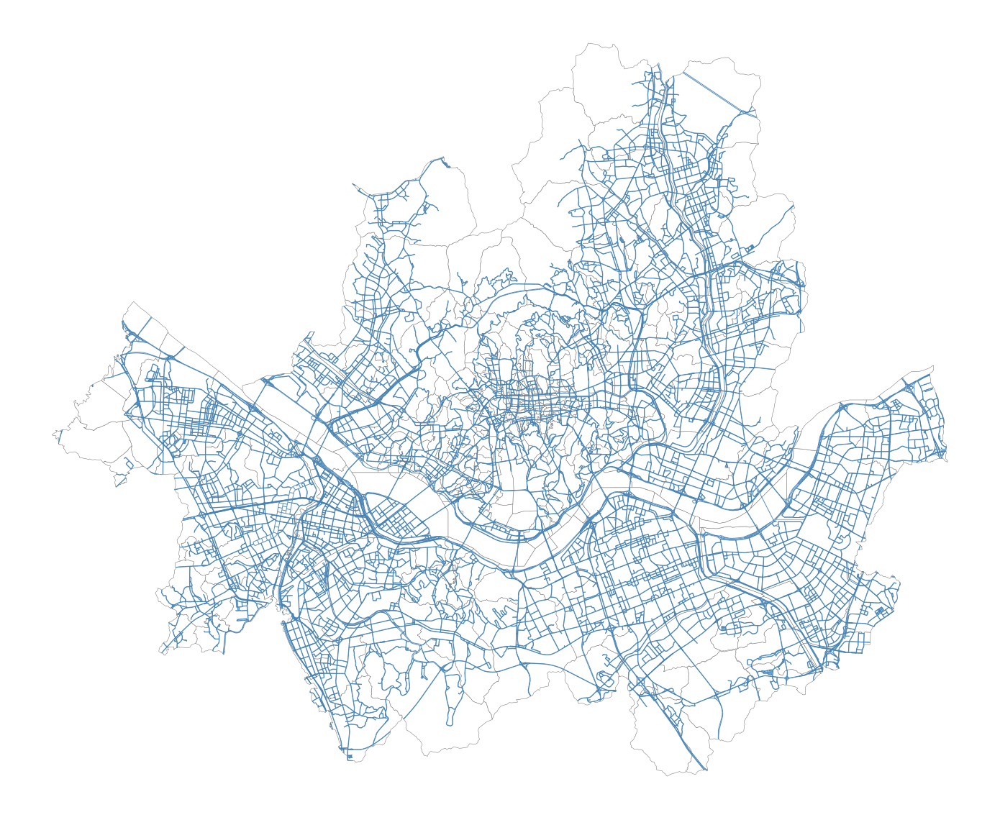

In [141]:
fig, ax = plt.subplots(figsize=(14, 14))

adm.plot(
    ax=ax,
    facecolor="white",
    edgecolor="gray",
    linewidth=0.4,
    zorder=1
)

link_seoul.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.7,
    alpha=0.9,
    zorder=2
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [ ]:
# 저장
link_seoul.to_file("shp/link_seoul.geojson", driver="GeoJSON", encoding="utf-8")


In [32]:

# 다시 불러오기
link_seoul_geojson = gpd.read_file("shp/link_seoul.geojson")

print(link_seoul_geojson.shape)
print(link_seoul_geojson.crs)
link_seoul_geojson.head()

(63653, 22)
EPSG:5186


,LINK_ID,F_NODE,T_NODE,LANES,ROAD_RANK,ROAD_TYPE,ROAD_NO,ROAD_NAME,ROAD_USE,MULTI_LINK,...,REST_VEH,REST_W,REST_H,C-ITS,LENGTH,UPDATEDATE,REMARK,HIST_TYPE,HISTREMARK,geometry
0,2130027000,2130009001,2130009801,2,107,000,-,광남로,0,0,...,0,0,0,0,243.507299,20250512,NaN,LINK0003,NaN,"LINESTRING (186278.661 541587.399, 186287.416 ..."
1,2130027100,2130009802,2130009004,2,107,000,-,광남로,0,0,...,0,0,0,0,243.554712,20250512,NaN,LINK0003,NaN,"LINESTRING (186275.478 541667.35, 186268.25 54..."
2,1160017700,2130009801,1160005302,2,107,000,-,광남로,0,0,...,0,0,0,0,19.965880,20250512,NaN,LINK0003,NaN,"LINESTRING (186287.416 541666.067, 186289.527 ..."
3,1160017800,1160005303,2130009802,2,107,000,-,광남로,0,0,...,0,0,0,0,19.918833,20250512,NaN,LINK0003,NaN,"LINESTRING (186277.529 541687.163, 186275.478 ..."
4,1160017900,1160005302,2130010002,2,104,003,-,광화로,0,0,...,0,0,0,0,32.807777,20250512,NaN,LINK0003,NaN,"LINESTRING (186289.527 541685.921, 186320.096 ..."


In [ ]:
# 저장
node_seoul.to_file("shp/node_seoul.geojson", driver="GeoJSON", encoding="utf-8")

In [33]:
# 다시 불러오기
node_seoul_geojson = gpd.read_file("shp/node_seoul.geojson")

print(node_seoul_geojson.shape)
print(node_seoul_geojson.crs)
node_seoul_geojson.head()

(46071, 9)
EPSG:5186


,NODE_ID,NODE_TYPE,NODE_NAME,TURN_P,UPDATEDATE,REMARK,HIST_TYPE,HISTREMARK,geometry
0,2130010002,105,구로구-광명시,0,20250512,None,NODE0001,None,POINT (186320.096 541674.01)
1,2130009801,105,구로구-광명시,0,20250512,None,NODE0001,None,POINT (186287.416 541666.067)
2,2130009802,105,구로구-광명시,0,20250512,None,NODE0001,None,POINT (186275.478 541667.35)
3,1160005302,101,광화교삼거리,0,20250512,None,NODE0001,None,POINT (186289.527 541685.921)
4,1160005303,101,광화교삼거리,0,20250512,None,NODE0001,None,POINT (186277.529 541687.163)


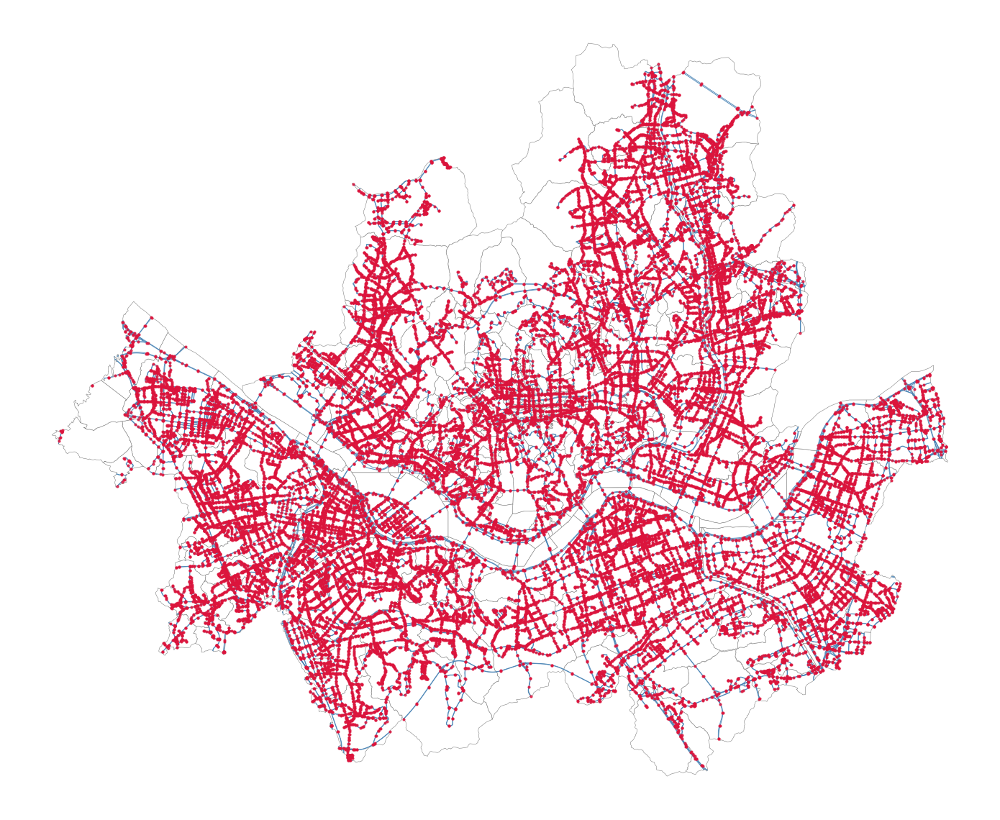

In [34]:
node_seoul_geojson = gpd.read_file("shp/node_seoul.geojson")
link_seoul_geojson = gpd.read_file("shp/link_seoul.geojson")


fig, ax = plt.subplots(figsize=(14, 14))

adm.plot(
    ax=ax,
    facecolor="white",
    edgecolor="gray",
    linewidth=0.4,
    zorder=1
)

link_seoul_geojson.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.7,
    alpha=0.9,
    zorder=2
)

node_seoul_geojson.plot(
    ax=ax,
    color="crimson",
    markersize=4,
    alpha=0.8,
    zorder=3
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [35]:
link_seoul_geojson

,LINK_ID,F_NODE,T_NODE,LANES,ROAD_RANK,ROAD_TYPE,ROAD_NO,ROAD_NAME,ROAD_USE,MULTI_LINK,...,REST_VEH,REST_W,REST_H,C-ITS,LENGTH,UPDATEDATE,REMARK,HIST_TYPE,HISTREMARK,geometry
0,2130027000,2130009001,2130009801,2,107,000,-,광남로,0,0,...,0,0,0,0,243.507299,20250512,NaN,LINK0003,NaN,"LINESTRING (186278.661 541587.399, 186287.416 ..."
1,2130027100,2130009802,2130009004,2,107,000,-,광남로,0,0,...,0,0,0,0,243.554712,20250512,NaN,LINK0003,NaN,"LINESTRING (186275.478 541667.35, 186268.25 54..."
2,1160017700,2130009801,1160005302,2,107,000,-,광남로,0,0,...,0,0,0,0,19.965880,20250512,NaN,LINK0003,NaN,"LINESTRING (186287.416 541666.067, 186289.527 ..."
3,1160017800,1160005303,2130009802,2,107,000,-,광남로,0,0,...,0,0,0,0,19.918833,20250512,NaN,LINK0003,NaN,"LINESTRING (186277.529 541687.163, 186275.478 ..."
4,1160017900,1160005302,2130010002,2,104,003,-,광화로,0,0,...,0,0,0,0,32.807777,20250512,NaN,LINK0003,NaN,"LINESTRING (186289.527 541685.921, 186320.096 ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63648,2180105000,2180037001,2180037101,2,107,003,-,북한산로,0,0,...,0,0,0,0,37.374620,20250512,NaN,LINK0003,NaN,"LINESTRING (195367.057 562112.63, 195382.157 5..."
63649,2180104900,2180037102,2180037002,2,107,003,-,북한산로,0,0,...,0,0,0,0,31.788087,20250512,NaN,LINK0003,NaN,"LINESTRING (195390.486 562140.177, 195376.309 ..."
63650,2180376001,2180037101,2180129503,2,107,000,-,북한산로,0,0,...,0,0,0,0,224.174747,20250512,NaN,LINK0003,NaN,"LINESTRING (195398.115 562131.066, 195399.407 ..."
63651,2180375901,2180129504,2180037102,2,107,000,-,북한산로,0,0,...,0,0,0,0,230.058575,20250512,NaN,LINK0003,NaN,"LINESTRING (195392.079 562141.363, 195390.486 ..."


In [36]:
landuse_green = landuse[
    landuse["DGM_NM"].astype(str).str.contains("녹지", na=False)
].copy()

landuse_green.head()

,PRESENT_SN,LCLAS_CL,MLSFC_CL,SCLAS_CL,ATRB_SE,WTNNC_SN,NTFC_SN,DGM_NM,DGM_AR,DGM_LT,SIGNGU_SE,DRAWING_NO,CREATE_DAT,SHAPE_AREA,SHAPE_LEN,geometry,map_color
3,11000UQ111PS201912156263,UQA400,UQA430,NaN,UQA430,11000ARZ000000001111,NaN,자연녹지지역,366281.337850,8977.360668,11000,NaN,2019-12-15,366281.337625,8977.360638,"POLYGON ((189360.655 550033.99, 189371.105 550...",#6A994E
7,11000UQ111PS201912156243,UQA400,UQA430,NaN,UQA430,11000ARZ199612100199,11000NTC199612106538,자연녹지지역,24606.865302,1641.549206,11000,NaN,2019-12-15,24606.865302,1641.549206,"POLYGON ((190011.933 547988.088, 189989.593 54...",#6A994E
27,11000UQ111PS202007127177,UQA400,UQA430,NaN,UQA430,11000ARZ000000001111,NaN,자연녹지지역,97.996012,157.107986,11000,NaN,2020-07-12,97.996081,157.108025,"POLYGON ((198753.154 556652.971, 198751.954 55...",#6A994E
34,11000UQ111PS202007126661,UQA400,UQA430,NaN,UQA430,11000ARZ000000001111,NaN,자연녹지지역,2111.862991,641.964792,11000,NaN,2020-07-12,2111.868125,641.964768,"POLYGON ((184774.614 541853.215, 184628.865 54...",#6A994E
43,11000UQ111PS202007127170,UQA400,UQA430,NaN,UQA430,11000ARZ000000001111,NaN,자연녹지지역,478.881482,269.124580,11000,NaN,2020-07-12,478.881667,269.124641,"POLYGON ((195026.577 556183.615, 195029.398 55...",#6A994E


In [37]:
landuse_green.DGM_NM.unique()

<StringArray>
[          '자연녹지지역',           '생산녹지지역',           '보전녹지지역',
           '자역녹지지역', '녹번 제1-2지구 자연녹지지역',             '녹지지역',
    '녹번제1구역 자연녹지지역',            '자연녹지지']
Length: 8, dtype: str

In [38]:
landuse_green_dissolved = landuse_green.dissolve() # 하나의 폴리곤으로 디졸브
landuse_green_dissolved = landuse_green_dissolved.to_crs(adm.crs) # CRS 맞춤

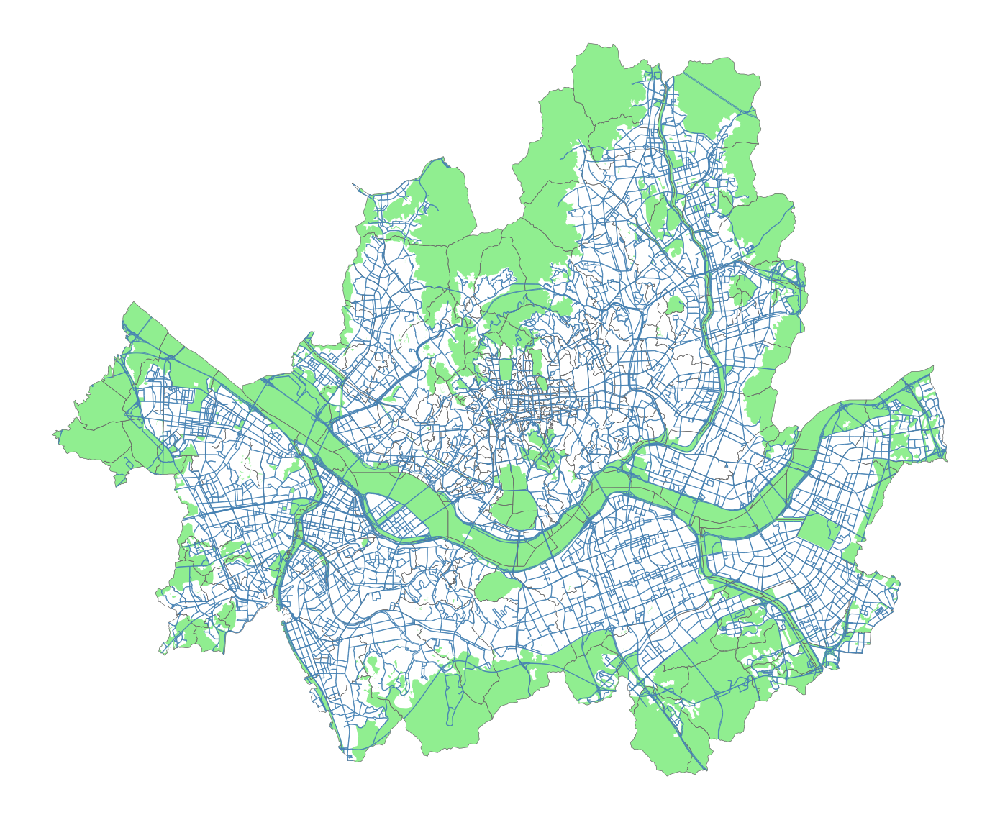

In [39]:

fig, ax = plt.subplots(figsize=(14, 14))

landuse_green_dissolved.plot(
    ax=ax,
    color="lightgreen",
    edgecolor="none",
    zorder=1
)

adm.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.5,
    zorder=2
)

link_seoul_geojson.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.7,
    alpha=0.9,
    zorder=2
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

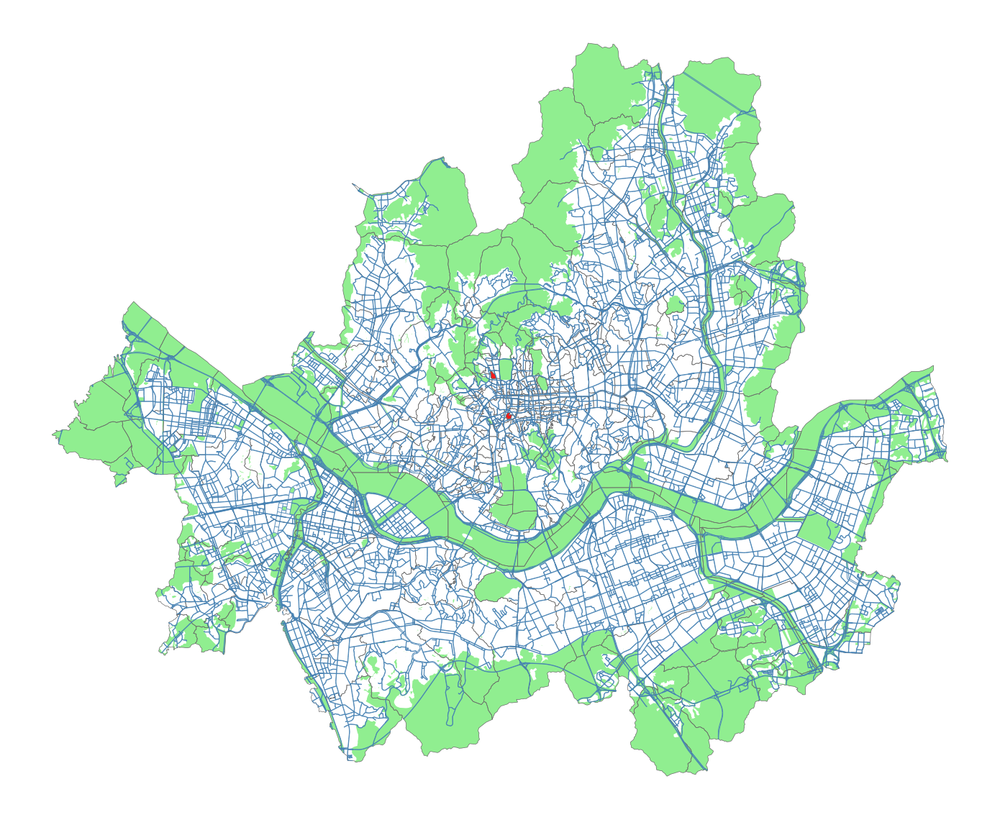

In [65]:
highlight_dongs = adm[adm["EMD_NM"].isin(["체부동", "북창동"])]

fig, ax = plt.subplots(figsize=(14, 14))

landuse_green_dissolved.plot(
    ax=ax,
    color="lightgreen",
    edgecolor="none",
    zorder=1
)

highlight_dongs.plot(
    ax=ax,
    color="red",
    edgecolor="none",
    alpha=0.9,
    zorder=2
)

adm.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.5,
    zorder=3
)

link_seoul_geojson.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.7,
    alpha=0.9,
    zorder=4
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [40]:
# 녹지지역을 제외한 법정동 경계와 도로망을 시각화하기 위해, 
# 녹지지역을 제외한 행정동 경계와 도로망을 클리핑합니다.
adm_no_green =  gpd.overlay(
    adm, landuse_green_dissolved[["geometry"]],
    how="difference"
)

link_no_green = gpd.overlay(
    link_seoul_geojson, landuse_green_dissolved[["geometry"]],
    how="difference"
)

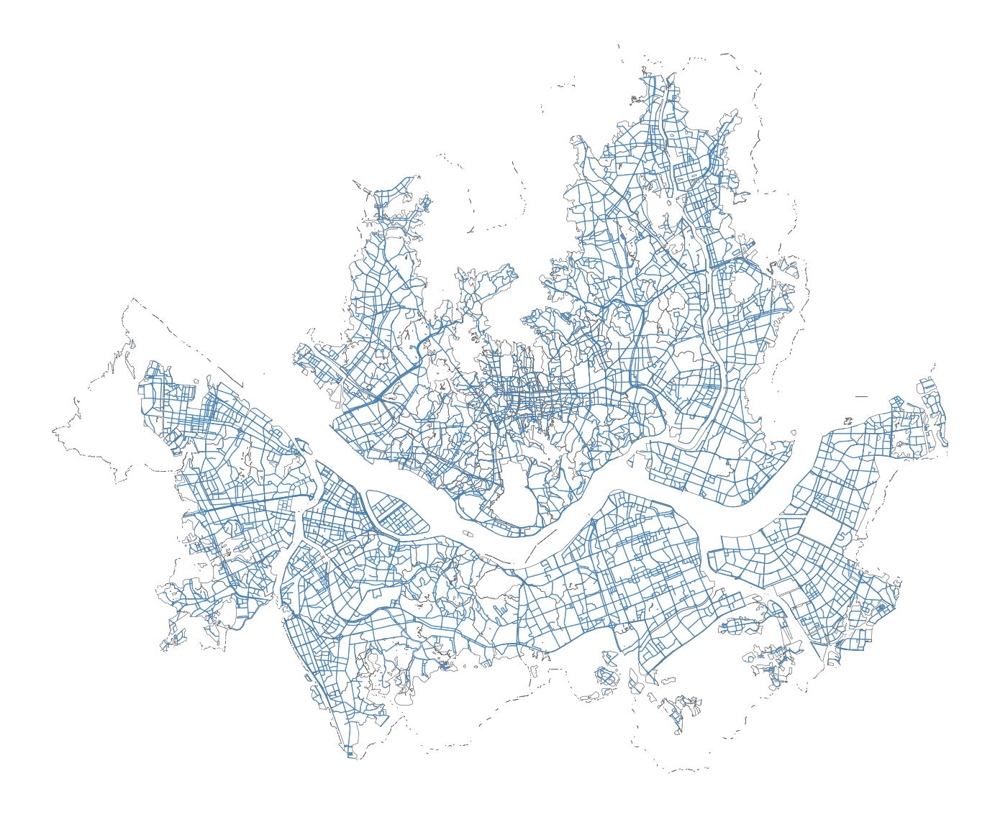

In [41]:

fig, ax = plt.subplots(figsize=(14, 14))


adm_no_green.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.5,
    zorder=2
)

link_no_green.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.7,
    alpha=0.9,
    zorder=2
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [42]:
# 거리 단위가 미터인지 CRS 확인
print(link_no_green.shape)
print(link_no_green.crs)

(58739, 22)
EPSG:5186


In [51]:
# 녹지지역을 제외한 도로망과 행정동 경계의 교차 영역을 계산합니다.
link_adm = gpd.overlay(
    link_no_green,
    adm_no_green,
    how="intersection",
    keep_geom_type=True
)

print(link_adm.shape)
link_adm.head()

(63677, 27)


,LINK_ID,F_NODE,T_NODE,LANES,ROAD_RANK,ROAD_TYPE,ROAD_NO,ROAD_NAME,ROAD_USE,MULTI_LINK,...,UPDATEDATE,REMARK,HIST_TYPE,HISTREMARK,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,dong_area,geometry
0,1160088200,2420058901,1160047803,3,104,004,-,서해안로,0,0,...,20250512,NaN,LINK0003,NaN,1153011200,11530,항동,52.0,1.446921e+06,"LINESTRING (183755.621 541670.299, 183766.084 ..."
1,2420265400,2420064902,2420357600,1,107,000,-,연동로,0,0,...,20250512,NaN,LINK0003,NaN,1153011200,11530,항동,52.0,1.446921e+06,"LINESTRING (184354.242 541873.127, 184354.096 ..."
2,2420196606,2420357500,2420064901,1,107,000,-,연동로,0,0,...,20250512,NaN,LINK1007,2420196600,1153011200,11530,항동,52.0,1.446921e+06,"LINESTRING (184366.239 541868.545, 184366.116 ..."
3,1160270400,2420064901,1160116502,1,104,000,-,연동로,0,0,...,20250512,NaN,LINK0003,NaN,1153011200,11530,항동,52.0,1.446921e+06,"LINESTRING (184366.23 541872.611, 184367.664 5..."
4,1160270500,1160116503,2420064902,1,104,000,-,연동로,0,0,...,20250512,NaN,LINK0003,NaN,1153011200,11530,항동,52.0,1.446921e+06,"MULTILINESTRING ((184361.154 542023.505, 18435..."


In [ ]:
# 녹지와 교차하는 영역 삭제하고 체부동, 북창동의 링크가 남지 않았음.
missing_codes = ["1111011200", "1114011300"]

link_adm[link_adm["EMD_CD"].isin(missing_codes)]

,LINK_ID,F_NODE,T_NODE,LANES,ROAD_RANK,ROAD_TYPE,ROAD_NO,ROAD_NAME,ROAD_USE,MULTI_LINK,...,UPDATEDATE,REMARK,HIST_TYPE,HISTREMARK,EMD_CD,COL_ADM_SE,EMD_NM,SGG_OID,dong_area,geometry


In [53]:
from shapely.geometry import LineString, MultiLineString
from shapely.ops import linemerge

# MultiLineString을 개별 LineString 행으로 분리
link_adm_parts = link_adm.explode(
    index_parts=False,
    ignore_index=True
)

# 선 도형만 유지
link_adm_parts = link_adm_parts[
    link_adm_parts.geometry.geom_type == "LineString"
].copy()

# 선 길이와 양 끝점 직선거리 재계산
link_adm_parts["line_length"] = link_adm_parts.geometry.length

link_adm_parts["straight_distance"] = link_adm_parts.geometry.apply(
    lambda geom: np.hypot(
        geom.coords[-1][0] - geom.coords[0][0],
        geom.coords[-1][1] - geom.coords[0][1]
    )
)

link_adm_parts["curvature_index"] = (
    1
    - link_adm_parts["straight_distance"]
      / link_adm_parts["line_length"]
)

print(link_adm_parts["straight_distance"].isna().sum())

0


In [56]:
length_by_dong = (
    link_adm_parts
    .groupby(["EMD_CD", "EMD_NM"])[["line_length", "straight_distance"]]
    .sum()
    .reset_index()
)
length_by_dong

,EMD_CD,EMD_NM,line_length,straight_distance
0,1111010100,청운동,3514.910051,3403.036771
1,1111010200,신교동,743.181920,720.703622
2,1111010300,궁정동,1368.933239,1367.230413
3,1111010400,효자동,856.322421,853.883281
4,1111010500,창성동,1212.816440,1211.719165
...,...,...,...,...
460,1174010600,둔촌동,13941.863581,13709.762474
461,1174010700,암사동,14400.815172,14340.437092
462,1174010800,성내동,31526.032712,31412.057665
463,1174010900,천호동,21332.302892,21242.566244


In [ ]:
length_by_dong["sinuosity_index"] = (
    length_by_dong["line_length"]
    / length_by_dong["straight_distance"]
)
length_by_dong

,EMD_CD,EMD_NM,line_length,straight_distance,sinuosity_index
0,1111010100,청운동,3514.910051,3403.036771,1.032875
1,1111010200,신교동,743.181920,720.703622,1.031189
2,1111010300,궁정동,1368.933239,1367.230413,1.001245
3,1111010400,효자동,856.322421,853.883281,1.002857
4,1111010500,창성동,1212.816440,1211.719165,1.000906
...,...,...,...,...,...
460,1174010600,둔촌동,13941.863581,13709.762474,1.016930
461,1174010700,암사동,14400.815172,14340.437092,1.004210
462,1174010800,성내동,31526.032712,31412.057665,1.003628
463,1174010900,천호동,21332.302892,21242.566244,1.004224


In [59]:
adm_no_green = adm_no_green.merge(
    length_by_dong,
    on="EMD_CD",
    how="left"
)
adm_no_green

,EMD_CD,COL_ADM_SE,EMD_NM_x,SGG_OID,geometry,dong_area,EMD_NM_y,line_length,straight_distance,sinuosity_index
0,1111010300,11110,궁정동,1034.0,"MULTIPOLYGON (((197388.365 553851.258, 197397....",7.332495e+04,궁정동,1368.933239,1367.230413,1.001245
1,1111012000,11110,신문로1가,1032.0,"POLYGON ((197513.143 552250.913, 197519.052 55...",6.576601e+04,신문로1가,2208.129182,2205.591764,1.001150
2,1111016700,11110,충신동,375.0,"POLYGON ((200756.029 553021.646, 200757.04 553...",1.282341e+05,충신동,1435.034642,1415.273772,1.013963
3,1111018500,11110,홍지동,374.0,"MULTIPOLYGON (((196038.247 556064.743, 196048....",3.558291e+05,홍지동,3066.490776,2834.641240,1.081791
4,1111015400,11110,장사동,368.0,"POLYGON ((199319.607 552274.718, 199334.592 55...",5.763400e+04,장사동,613.863318,613.851448,1.000019
...,...,...,...,...,...,...,...,...,...,...
462,1174010800,11740,성내동,354.0,"POLYGON ((210911.684 548880.836, 210930.895 54...",1.957705e+06,성내동,31526.032712,31412.057665,1.003628
463,1174010500,11740,길동,355.0,"POLYGON ((213221.602 548595.267, 213175.357 54...",1.612791e+06,길동,14369.071384,14248.711347,1.008447
464,1174011000,11740,강일동,377.0,"MULTIPOLYGON (((215645.723 553474.815, 215645....",2.267709e+06,강일동,15341.678969,15085.370001,1.016991
465,1174010100,11740,명일동,361.0,"MULTIPOLYGON (((212776.265 550613.394, 212783....",1.572132e+06,명일동,16309.503956,16183.174523,1.007806


In [60]:
adm_no_green.count()

EMD_CD               467
COL_ADM_SE           467
EMD_NM_x             467
SGG_OID              467
geometry             467
dong_area            467
EMD_NM_y             465
line_length          465
straight_distance    465
sinuosity_index      465
dtype: int64

In [61]:
missing_dongs = adm_no_green.loc[
    ~adm_no_green["EMD_CD"].astype(str).isin(
        length_by_dong["EMD_CD"].astype(str)
    ),
    ["EMD_CD", "EMD_NM_x"]
]

missing_dongs

,EMD_CD,EMD_NM_x
42,1111011200,체부동
120,1114011300,북창동


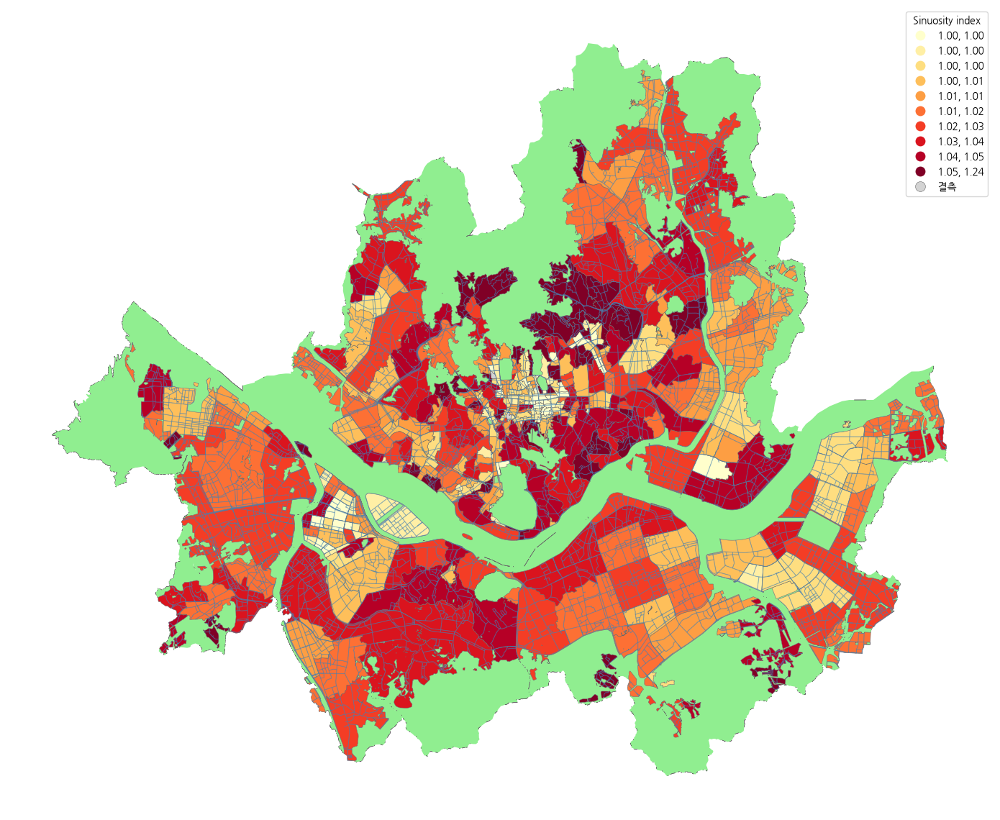

In [67]:
fig, ax = plt.subplots(figsize=(14, 14))

landuse_green_dissolved.plot(
    ax=ax,
    color="lightgreen",
    edgecolor="none",
    zorder=1
)

adm_no_green.plot(
    ax=ax,
    column="sinuosity_index",
    scheme="Quantiles",
    k=10,
    cmap="YlOrRd",
    legend=True,
    edgecolor="dimgray",
    linewidth=0.4,
    missing_kwds={"color": "lightgray", "label": "결측"},
    legend_kwds={"title": "Sinuosity index"},
    zorder=2
)

link_no_green.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.4,
    alpha=0.7,
    zorder=3
)

ax.set_axis_off()
plt.tight_layout()
plt.show()